# Import libraries

In [175]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (accuracy_score, precision_score, recall_score,f1_score,
balanced_accuracy_score, confusion_matrix, roc_auc_score, classification_report)
from sklearn.feature_selection import mutual_info_classif

from xgboost import XGBClassifier

# Import Data

In [5]:
# Project set-up
horizons = [1, 5, 21, 63]

layers = ["raw","technical","market","macro","bs"]

sliding_window = 252
test_window = 126
step_size = 126

train_cutoff = pd.Timestamp("2024-09-01")

data_dir = Path("../data/raw")

In [9]:
#Load data previously made 
datasets = {"raw": pd.read_csv(data_dir / "amzn_raw.csv"),
            "technical": pd.read_csv(data_dir / "amzn_technical.csv"),
            "market": pd.read_csv(data_dir / "amzn_market.csv"),
            "macro": pd.read_csv(data_dir / "amzn_macro.csv"),
            "bs": pd.read_csv(data_dir / "amzn_bs.csv")}

# Prepare & Inspect Data

In [23]:
for layer, df in datasets.items():
    df["Date"] = pd.to_datetime(df["Date"])
    df.sort_values("Date", inplace=True)
    df.reset_index(drop=True, inplace=True)

    print(f"\n{layer.upper()}")
    print("Shape:", df.shape)
    print("Date range:", df["Date"].min(), "to", df["Date"].max())
    print("Duplicate dates:", df["Date"].duplicated().sum())


RAW
Shape: (2513, 18)
Date range: 2016-09-01 00:00:00 to 2026-09-01 00:00:00
Duplicate dates: 0

TECHNICAL
Shape: (2513, 33)
Date range: 2016-09-01 00:00:00 to 2026-09-01 00:00:00
Duplicate dates: 0

MARKET
Shape: (2513, 45)
Date range: 2016-09-01 00:00:00 to 2026-09-01 00:00:00
Duplicate dates: 0

MACRO
Shape: (2513, 53)
Date range: 2016-09-01 00:00:00 to 2026-09-01 00:00:00
Duplicate dates: 0

BS
Shape: (2513, 57)
Date range: 2016-09-01 00:00:00 to 2026-09-01 00:00:00
Duplicate dates: 0


In [27]:
#Check if we have all our target columns 

target_cols = [f"direction_{h}d" for h in horizons]

label_end_cols = [f"label_end_{h}d" for h in horizons]

for layer, df in datasets.items():
    missing = [col for col in target_cols + label_end_cols if col not in df.columns]

    print(f"{layer}: Missing columns = {missing}")

raw: Missing columns = []
technical: Missing columns = []
market: Missing columns = []
macro: Missing columns = []
bs: Missing columns = []


In [39]:
#Convert label-end columns to datetime to use later
for layer, df in datasets.items():
    for h in horizons:
        col = f"label_end_{h}d"
        df[col] = pd.to_datetime(df[col], errors="coerce")

In [41]:
#Generate fold schedule - use bs layer as common ground

calendar = datasets["bs"]["Date"].drop_duplicates().sort_values().reset_index(drop=True)

# Only use observations before the final holdout
dev_dates = calendar[calendar < train_cutoff].reset_index(drop=True)

folds = []
fold_id = 1

test_start_idx = sliding_window #252 (1 year)

while test_start_idx + test_window <= len(dev_dates): 

    train_start_idx = test_start_idx - sliding_window
    test_end_idx = test_start_idx + test_window

    train_start = dev_dates.iloc[train_start_idx]
    train_end = dev_dates.iloc[test_start_idx - 1]

    test_start = dev_dates.iloc[test_start_idx]
    test_end = dev_dates.iloc[test_end_idx - 1]

    folds.append({"Fold": fold_id,
                  "Train_Start": train_start,
                  "Train_End": train_end,
                  "Test_Start": test_start,
                  "Test_End": test_end })

    fold_id += 1
    test_start_idx += step_size

folds_df = pd.DataFrame(folds)
folds_df

,Fold,Train_Start,Train_End,Test_Start,Test_End
0,1,2016-09-01,2017-08-31,2017-09-01,2018-03-05
1,2,2017-03-06,2018-03-05,2018-03-06,2018-08-31
2,3,2017-09-01,2018-08-31,2018-09-04,2019-03-06
3,4,2018-03-06,2019-03-06,2019-03-07,2019-09-04
4,5,2018-09-04,2019-09-04,2019-09-05,2020-03-05
5,6,2019-03-07,2020-03-05,2020-03-06,2020-09-02
6,7,2019-09-05,2020-09-02,2020-09-03,2021-03-05
7,8,2020-03-06,2021-03-05,2021-03-08,2021-09-02
8,9,2020-09-03,2021-09-02,2021-09-03,2022-03-04
9,10,2021-03-08,2022-03-04,2022-03-07,2022-09-02


In [43]:
#Ensure all layer datasets share same trading dates
base_dates = datasets["bs"]["Date"]

for layer, df in datasets.items():
    same_dates = df["Date"].equals(base_dates)
    print(f"{layer}: Same dates as BS = {same_dates}")

raw: Same dates as BS = True
technical: Same dates as BS = True
market: Same dates as BS = True
macro: Same dates as BS = True
bs: Same dates as BS = True


In [45]:
# Creat a function to generate train/test data for each fold n horizon
# purge train observations w target that may extend into the region of our target date

def get_fold_data(df, fold, horizon):
    target_col = f"direction_{horizon}d"
    label_end_col = f"label_end_{horizon}d"

    # Training window: only the 252 scheduled training observations
    train_mask = ((df["Date"] >= fold["Train_Start"]) &
                  (df["Date"] <= fold["Train_End"]) &
                  df[target_col].notna() &
                  df[label_end_col].notna() &
                  (df[label_end_col] < fold["Test_Start"]))

    # Testing window: 126 scheduled test observations
    test_mask = ((df["Date"] >= fold["Test_Start"]) &
                 (df["Date"] <= fold["Test_End"]) &
                 df[target_col].notna())

    train_df = df.loc[train_mask].copy()
    test_df = df.loc[test_mask].copy()

    return train_df, test_df

In [47]:
#Check sample sizes after purging
fold_sizes = []

for _, fold in folds_df.iterrows():

    for horizon in horizons:

        train_df, test_df = get_fold_data(datasets["bs"], fold, horizon)

        fold_sizes.append({"Fold": fold["Fold"],
                           "Horizon": horizon,
                           "Train_Start": fold["Train_Start"],
                           "Train_End": fold["Train_End"],
                           "Test_Start": fold["Test_Start"],
                           "Test_End": fold["Test_End"],
                           "Train_N": len(train_df),
                           "Test_N": len(test_df) })

fold_sizes_df = pd.DataFrame(fold_sizes)
display(fold_sizes_df)

,Fold,Horizon,Train_Start,Train_End,Test_Start,Test_End,Train_N,Test_N
0,1,1,2016-09-01,2017-08-31,2017-09-01,2018-03-05,251,126
1,1,5,2016-09-01,2017-08-31,2017-09-01,2018-03-05,247,126
2,1,21,2016-09-01,2017-08-31,2017-09-01,2018-03-05,231,126
3,1,63,2016-09-01,2017-08-31,2017-09-01,2018-03-05,189,126
4,2,1,2017-03-06,2018-03-05,2018-03-06,2018-08-31,251,126
5,2,5,2017-03-06,2018-03-05,2018-03-06,2018-08-31,247,126
6,2,21,2017-03-06,2018-03-05,2018-03-06,2018-08-31,231,126
7,2,63,2017-03-06,2018-03-05,2018-03-06,2018-08-31,189,126
8,3,1,2017-09-01,2018-08-31,2018-09-04,2019-03-06,251,126
9,3,5,2017-09-01,2018-08-31,2018-09-04,2019-03-06,247,126


In [49]:
#Check how much data remain unused (due to chronological purge)
print("Development data ends:", dev_dates.max())
print("Last test fold ends:", folds_df["Test_End"].max())

print(
    "Remaining observations:",
    (dev_dates > folds_df["Test_End"].max()).sum()
)

print("Number of folds:", len(folds_df))

Development data ends: 2024-08-30 00:00:00
Last test fold ends: 2024-03-07 00:00:00
Remaining observations: 122
Number of folds: 13


In [51]:
#make use of unused data and make shorter folds near the end

last_test_start_idx = len(dev_dates) - 122

train_start_idx = last_test_start_idx - sliding_window
test_end_idx = len(dev_dates)

partial_fold = {"Fold": len(folds_df) + 1,
                "Train_Start": dev_dates.iloc[train_start_idx],
                "Train_End": dev_dates.iloc[last_test_start_idx - 1],
                "Test_Start": dev_dates.iloc[last_test_start_idx],
                "Test_End": dev_dates.iloc[test_end_idx - 1]}

folds_df = pd.concat([folds_df, pd.DataFrame([partial_fold])],ignore_index=True)

display(folds_df.tail(3))

,Fold,Train_Start,Train_End,Test_Start,Test_End
11,12,2022-03-07,2023-03-07,2023-03-08,2023-09-06
12,13,2022-09-06,2023-09-06,2023-09-07,2024-03-07
13,14,2023-03-08,2024-03-07,2024-03-08,2024-08-30


In [57]:
#Recalc sample size
fold_sizes = []

for _, fold in folds_df.iterrows():
    for horizon in horizons:

        train_df, test_df = get_fold_data(datasets["bs"], fold, horizon)

        fold_sizes.append({"Fold": fold["Fold"],
                           "Horizon": horizon,
                           "Train_Start": fold["Train_Start"],
                           "Train_End": fold["Train_End"],
                           "Test_Start": fold["Test_Start"],
                           "Test_End": fold["Test_End"],
                           "Train_N": len(train_df),
                           "Test_N": len(test_df) })

fold_sizes_df = pd.DataFrame(fold_sizes)
display(fold_sizes_df.tail(4))

,Fold,Horizon,Train_Start,Train_End,Test_Start,Test_End,Train_N,Test_N
52,14,1,2023-03-08,2024-03-07,2024-03-08,2024-08-30,251,122
53,14,5,2023-03-08,2024-03-07,2024-03-08,2024-08-30,247,122
54,14,21,2023-03-08,2024-03-07,2024-03-08,2024-08-30,231,122
55,14,63,2023-03-08,2024-03-07,2024-03-08,2024-08-30,189,122


In [73]:
# Our feature sets

# Layer 1: Raw OHLCV
raw_features = ["Open", "High", "Low", "Adj_Close", "Volume"]

# Layer 2: Technical indicators
technical_features = raw_features + ["Log_Return_1d",
                                     "Log_Return_5d",
                                     "Log_Return_21d",
                                     "Log_Return_63d",
                                     "Price_SMA20",
                                     "Price_SMA50",
                                     "Price_SMA200",
                                     "RSI14",
                                     "ADX14",
                                     "Rolling_Volatility_10d",
                                     "Rolling_Volatility_60d",
                                     "Relative_Volume_20d",
                                     "Relative_Volume_60d",
                                     "Bollinger_PctB",
                                     "OBV_Slope_10d"]

# Layer 3: Market information
market_features = technical_features + ["SPY_LogRet_1d",
                                        "SPY_LogRet_5d",
                                        "SPY_LogRet_21d",
                                        "SPY_LogRet_63d",
                                        "SPY_Volatility_20d",
                                        "SPY_SMA50",
                                        "Relative_Return_1d",
                                        "Relative_Return_5d",
                                        "Relative_Return_21d",
                                        "Relative_Return_63d",
                                        "Rolling_Beta_SPY_20d",
                                        "Rolling_Beta_SPY_60d" ]

# Layer 4: Macroeconomic information
macro_features = market_features + ["Treasury_10Y_Yield",
                                    "Treasury_3M_Yield",
                                    "Treasury_10Y_Change_1d",
                                    "Treasury_10Y_Change_5d",
                                    "Treasury_10Y_2Y_Spread",
                                    "VIX",
                                    "VIX_Change_1d",
                                    "VIX_Change_5d",]

# Layer 5: Black-Scholes information
bs_features = macro_features + ["BS_Delta_ATM_30d",
                                "BS_Call_Price_ATM_%Spot_30d",
                                "BS_Delta_ATM_60d",
                                "BS_Call_Price_ATM_%Spot_60d" ]

feature_sets = {"raw": raw_features,
                "technical": technical_features,
                "market": market_features,
                "macro": macro_features,
                "bs": bs_features }

In [75]:
#Ensure every feature exists in corresponding datasets

for layer, features in feature_sets.items():

    missing = [col for col in features if col not in datasets[layer].columns]

    target_leakage = [col for col in features
                      if col.startswith(("direction_", "fwd_ret_", "label_end_"))]

    print(f"\n{layer.upper()}")
    print("Number of features:", len(features))
    print("Missing features:", missing)
    print("Target leakage:", target_leakage)


RAW
Number of features: 5
Missing features: []
Target leakage: []

TECHNICAL
Number of features: 20
Missing features: []
Target leakage: []

MARKET
Number of features: 32
Missing features: []
Target leakage: []

MACRO
Number of features: 40
Missing features: []
Target leakage: []

BS
Number of features: 44
Missing features: []
Target leakage: []


# Modeling

In [81]:
#Same build model function used in notebook 3 (expanding walk-forward)
def build_models():
    models={}
    
    #set sof models to use
    base_models = {
        "Naive Majority": DummyClassifier(strategy="most_frequent"),
        "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced",
                                                 random_state=42),
        "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, 
                                               class_weight="balanced_subsample", n_jobs=-1,
                                               random_state=42),
        "XGBoost": XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, 
                                subsample=0.8, colsample_bytree=0.8, objective="binary:logistic",
                                eval_metric="logloss", n_jobs=-1, random_state=42) }
    #sets of scaling techniques
    scalers = {
        "No Scaling": None,
        "StandardScaler": StandardScaler(),
        "RobustScaler": RobustScaler() }

    for model_name, base_model in base_models.items():
        #Naive model doesnt use scalers
        if model_name == "Naive Majority":
            models[model_name] = base_model
            continue
            
        for scaler_name, scaler in scalers.items():
            #build a separate pipeline for each configuration
            steps = []
            if scaler is not None:
                steps.append(("scaler", scaler))

            steps.append(("model",clone( base_model)))
            
            models[f"{model_name} | {scaler_name}"] = Pipeline(steps)
            
    return models

In [88]:
#Same metric function used in notebook 3 to set up scoring metrics

def metric_row(y_true, y_pred, y_prob=None):
    
    out = {"Accuracy": accuracy_score(y_true, y_pred),
           "Balanced_Accuracy": balanced_accuracy_score(y_true, y_pred),
           "Up_Precision": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
           "Up_Recall": recall_score(y_true, y_pred, pos_label=1, zero_division=0),
           "Up_F1": f1_score(y_true, y_pred, pos_label=1, zero_division=0),}
    
    out["ROC_AUC"] = (roc_auc_score(y_true, y_prob) if y_prob is not None 
                      and len(np.unique(y_true)) == 2 else np.nan)
    return out

In [83]:
#Create models
models = build_models()

for name, model in models.items():
    print(name, ":", type(model).__name__)

print("\nTotal models:", len(models))

Naive Majority : DummyClassifier
Logistic Regression | No Scaling : Pipeline
Logistic Regression | StandardScaler : Pipeline
Logistic Regression | RobustScaler : Pipeline
Random Forest | No Scaling : Pipeline
Random Forest | StandardScaler : Pipeline
Random Forest | RobustScaler : Pipeline
XGBoost | No Scaling : Pipeline
XGBoost | StandardScaler : Pipeline
XGBoost | RobustScaler : Pipeline

Total models: 10


In [100]:
#Main model train/validation loop

all_metrics = []
all_predictions = []
all_reports = []
all_confusions = []

for layer_name, feature_cols in feature_sets.items():
    
    df = datasets[layer_name]
    print(f"\n {layer_name.upper()}")

    for h in horizons:

        target_col = f"direction_{h}d"
        label_end_col = f"label_end_{h}d"

        model_dict = build_models()

        for _, fold in folds_df.iterrows():

            fold_num = fold["Fold"]
            fold_start = fold["Test_Start"]
            fold_end = fold["Test_End"]

            # Test observations within the test window
            test_mask = (df["Date"].between(fold_start, fold_end, inclusive="both")
                & df[target_col].notna())

            test_df = df.loc[test_mask].copy()

            if test_df.empty:
                continue

            # Training observations must have matured labels
            train_mask = ( (df["Date"] >= fold["Train_Start"])
                          & (df["Date"] <= fold["Train_End"])
                          & df[target_col].notna()
                          & df[label_end_col].notna()
                          & (df[label_end_col] < fold_start) )

            train_df = df.loc[train_mask].copy()
            
            if len(train_df) < 150: #the amount the train length must start out with
                continue

            # Set up train/test features and targets
            x_train = train_df[feature_cols]
            y_train = train_df[target_col].astype(int)
            x_test = test_df[feature_cols]
            y_test = test_df[target_col].astype(int)

            for model_name, estimator in model_dict.items():

                # Only Logistic Regression requires complete feature rows
                #Missing handling
                need_complete_rows = model_name.startswith("Logistic Regression")

                if need_complete_rows:
                    train_valid = x_train.notna().all(axis=1)
                    test_valid = x_test.notna().all(axis=1)

                    x_train_model = x_train.loc[train_valid]
                    y_train_model = y_train.loc[train_valid]
                    x_test_model = x_test.loc[test_valid]
                    y_test_model = y_test.loc[test_valid]
                else:
                    x_train_model = x_train
                    y_train_model = y_train
                    x_test_model = x_test
                    y_test_model = y_test

                # Safeguards
                if len(y_train_model) < 150 or len(y_test_model) == 0:
                    continue

                if y_train_model.nunique() < 2:
                    continue

                # Fit and predict
                if model_name == "Naive Majority":
                    estimator.fit(np.zeros((len(y_train_model), 1)),y_train_model)

                    pred = estimator.predict(np.zeros((len(y_test_model), 1))).astype(int)

                    prob = None

                else:
                    estimator.fit(x_train_model, y_train_model)

                    pred = estimator.predict(x_test_model).astype(int)

                    prob = None

                    if hasattr(estimator, "predict_proba"):
                        try:
                            prob = estimator.predict_proba(x_test_model)[:, 1]
                        except (ValueError, IndexError):
                            prob = None

                # Metrics
                row = {"Layer": layer_name,
                       "Horizon": h,
                       "Fold": fold_num,
                       "Test_Start": fold_start,
                       "Test_End": fold_end,
                       "Model": model_name,
                       "N_Train": len(y_train_model),
                       "N_Test": len(y_test_model),
                       "N_Train_Excluded_Missing": len(y_train) - len(y_train_model),
                       "N_Test_Excluded_Missing": len(y_test) - len(y_test_model),
                        **metric_row(y_test_model, pred, prob) }

                all_metrics.append(row)

                # Predictions
                pred_frame = test_df.loc[y_test_model.index, ["Date"]].copy()

                pred_frame["Layer"] = layer_name
                pred_frame["Horizon"] = h
                pred_frame["Fold"] = fold_num
                pred_frame["Model"] = model_name
                pred_frame["y_true"] = y_test_model.to_numpy()
                pred_frame["y_pred"] = pred
                pred_frame["y_prob_up"] = (prob if prob is not None else np.nan)

                all_predictions.append(pred_frame)

                # Classification report
                report = classification_report(y_test_model, pred, labels=[0,1],
                                               target_names=["Down", "Up"],
                                               output_dict=True,zero_division=0)

                all_reports.append({"Layer": layer_name,
                                    "Horizon": h,
                                    "Fold": fold_num,
                                    "Model": model_name,
                                    "Down_Precision": report["Down"]["precision"],
                                    "Down_Recall": report["Down"]["recall"],
                                    "Down_F1": report["Down"]["f1-score"],
                                    "Up_Precision_Report": report["Up"]["precision"],
                                    "Up_Recall_Report": report["Up"]["recall"],
                                    "Up_F1_Report": report["Up"]["f1-score"],
                                    "Macro_F1": report["macro avg"]["f1-score"],
                                    "Weighted_F1": report["weighted avg"]["f1-score"] })

                # Confusion matrix
                cm = confusion_matrix(y_test_model, pred, labels=[0,1])

                all_confusions.append({"Layer": layer_name,
                                       "Horizon": h,
                                       "Fold": fold_num,
                                       "Model": model_name,
                                       "TN": cm[0, 0],
                                       "FP": cm[0, 1],
                                       "FN": cm[1, 0],
                                       "TP": cm[1, 1]})

        print(f"Completed horizon: {h}d")

# Convert results to DataFrames
metrics_df = pd.DataFrame(all_metrics)

predictions_df = (pd.concat(all_predictions, ignore_index=True)
                  if all_predictions else pd.DataFrame())

reports_df = pd.DataFrame(all_reports)
confusions_df = pd.DataFrame(all_confusions)

if metrics_df.empty:
    raise RuntimeError("No metrics were generated")

print("\nSliding-window evaluation completed!")
print("Metrics:", metrics_df.shape)
print("Predictions:", predictions_df.shape)
print("Reports:", reports_df.shape)
print("Confusions:", confusions_df.shape)


 RAW
Completed horizon: 1d
Completed horizon: 5d
Completed horizon: 21d


/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:386: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2458: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2458: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2458: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2458: UserWarning: y_pred contains classes not in y_true
  warnings.warn

Completed horizon: 63d

 TECHNICAL
Completed horizon: 1d
Completed horizon: 5d
Completed horizon: 21d


/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:386: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2458: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/opt/anaconda3/lib/python3.12/site-packages/sklearn/utils/extmath.py:1137: RuntimeWarning: invalid value encountered in divide
  updated_mean = (last_sum + new_sum) / updated_sample_count
/opt/anaconda3/lib/python3.12/site-packages/sklearn/utils/extmath.py:1142: RuntimeWarning: invalid value encountered in divide
  T = new_sum / new_sample_count
/opt/anaconda3/lib/python3.12/site-packages/sklearn/utils/extmath.py:1162: RuntimeWarning: invalid value encountered in divide
  new_unnormalized_variance -= correction**2 / new_sample_coun

Completed horizon: 63d

 MARKET
Completed horizon: 1d
Completed horizon: 5d
Completed horizon: 21d


/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:386: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2458: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/opt/anaconda3/lib/python3.12/site-packages/sklearn/utils/extmath.py:1137: RuntimeWarning: invalid value encountered in divide
  updated_mean = (last_sum + new_sum) / updated_sample_count
/opt/anaconda3/lib/python3.12/site-packages/sklearn/utils/extmath.py:1142: RuntimeWarning: invalid value encountered in divide
  T = new_sum / new_sample_count
/opt/anaconda3/lib/python3.12/site-packages/sklearn/utils/extmath.py:1162: RuntimeWarning: invalid value encountered in divide
  new_unnormalized_variance -= correction**2 / new_sample_coun

Completed horizon: 63d

 MACRO
Completed horizon: 1d
Completed horizon: 5d
Completed horizon: 21d


/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:386: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2458: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/opt/anaconda3/lib/python3.12/site-packages/sklearn/utils/extmath.py:1137: RuntimeWarning: invalid value encountered in divide
  updated_mean = (last_sum + new_sum) / updated_sample_count
/opt/anaconda3/lib/python3.12/site-packages/sklearn/utils/extmath.py:1142: RuntimeWarning: invalid value encountered in divide
  T = new_sum / new_sample_count
/opt/anaconda3/lib/python3.12/site-packages/sklearn/utils/extmath.py:1162: RuntimeWarning: invalid value encountered in divide
  new_unnormalized_variance -= correction**2 / new_sample_coun

Completed horizon: 63d

 BS
Completed horizon: 1d
Completed horizon: 5d
Completed horizon: 21d


/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:386: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2458: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/opt/anaconda3/lib/python3.12/site-packages/sklearn/utils/extmath.py:1137: RuntimeWarning: invalid value encountered in divide
  updated_mean = (last_sum + new_sum) / updated_sample_count
/opt/anaconda3/lib/python3.12/site-packages/sklearn/utils/extmath.py:1142: RuntimeWarning: invalid value encountered in divide
  T = new_sum / new_sample_count
/opt/anaconda3/lib/python3.12/site-packages/sklearn/utils/extmath.py:1162: RuntimeWarning: invalid value encountered in divide
  new_unnormalized_variance -= correction**2 / new_sample_coun

Completed horizon: 63d

Sliding-window evaluation completed!
Metrics: (2690, 16)
Predictions: (338140, 8)
Reports: (2690, 12)
Confusions: (2690, 8)


In [122]:
#Check layer, horizon, and fold coverage
print("Layers:")
print(metrics_df["Layer"].value_counts().sort_index())

print("\nHorizons:")
print(metrics_df["Horizon"].value_counts().sort_index())

print("\nFolds:")
print(sorted(metrics_df["Fold"].unique()))

print("\nModels:")
print(metrics_df["Model"].value_counts())

print("\nUnique combinations:")
print(metrics_df[["Layer", "Horizon", "Fold", "Model"]].drop_duplicates().shape[0])

Layers:
Layer
bs           535
macro        535
market       535
raw          550
technical    535
Name: count, dtype: int64

Horizons:
Horizon
1     688
5     688
21    688
63    626
Name: count, dtype: int64

Folds:
[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]

Models:
Model
Naive Majority                          275
Random Forest | No Scaling              275
Random Forest | StandardScaler          275
Random Forest | RobustScaler            275
XGBoost | No Scaling                    275
XGBoost | StandardScaler                275
XGBoost | RobustScaler                  275
Logistic Regression | No Scaling        255
Logistic Regression | StandardScaler    255
Logistic Regression | RobustScaler      255
Name: count, dtype: int64

Unique combinations:
2690


In [118]:
# Expected number of model evaluations
expected = (len(feature_sets) * len(horizons) * len(folds_df) * len(build_models()))

print("Expected evaluations:", expected)
print("Actual evaluations:", len(metrics_df))
print("Skipped evaluations:", expected - actual)

Expected evaluations: 2800
Actual evaluations: 2690
Skipped evaluations: 110


In [114]:
#Check train/test sample sizes

metrics_df.groupby(["Horizon", "Model"])[["N_Train", 
                                          "N_Test"]].agg(["min", "mean", "max"]).round(1)

N_Train             N_Test  \
                                                 min   mean  max    min   
Horizon Model                                                             
1       Logistic Regression | No Scaling         178  246.6  251    122   
        Logistic Regression | RobustScaler       178  246.6  251    122   
        Logistic Regression | StandardScaler     178  246.6  251    122   
        Naive Majority                           251  251.0  251    122   
        Random Forest | No Scaling               251  251.0  251    122   
        Random Forest | RobustScaler             251  251.0  251    122   
        Random Forest | StandardScaler           251  251.0  251    122   
        XGBoost | No Scaling                     251  251.0  251    122   
        XGBoost | RobustScaler                   251  251.0  251    122   
        XGBoost | StandardScaler                 251  251.0  251    122   
5       Logistic Regression | No Scaling         174  242.6  247    122   
        Logistic Regression | RobustScaler       174  242.6  247    122   
        Logistic Regression | StandardScaler     174  242.6  247    122   
        Naive Majority                           247  247.0  247    122   
        Random Forest | No Scaling               247  247.0  247    122   
        Random Forest | RobustScaler             247  247.0  247    122   
        Random Forest | StandardScaler           247  247.0  247    122   
        XGBoost | No Scaling                     247  247.0  247    122   
        XGBoost | RobustScaler                   247  247.0  247    122   
        XGBoost | StandardScaler                 247  247.0  247    122   
21      Logistic Regression | No Scaling         158  226.6  231    122   
        Logistic Regression | RobustScaler       158  226.6  231    122   
        Logistic Regression | StandardScaler     158  226.6  231    122   
        Naive Majority                           231  231.0  231    122   
        Random Forest | No Scaling               231  231.0  231    122   
        Random Forest | RobustScaler             231  231.0  231    122   
        Random Forest | StandardScaler           231  231.0  231    122   
        XGBoost | No Scaling                     231  231.0  231    122   
        XGBoost | RobustScaler                   231  231.0  231    122   
        XGBoost | StandardScaler                 231  231.0  231    122   
63      Logistic Regression | No Scaling         189  189.0  189    122   
        Logistic Regression | RobustScaler       189  189.0  189    122   
        Logistic Regression | StandardScaler     189  189.0  189    122   
        Naive Majority                           189  189.0  189    122   
        Random Forest | No Scaling               189  189.0  189    122   
        Random Forest | RobustScaler             189  189.0  189    122   
        Random Forest | StandardScaler           189  189.0  189    122   
        XGBoost | No Scaling                     189  189.0  189    122   
        XGBoost | RobustScaler                   189  189.0  189    122   
        XGBoost | StandardScaler                 189  189.0  189    122   

                                                          
                                               mean  max  
Horizon Model                                             
1       Logistic Regression | No Scaling      125.7  126  
        Logistic Regression | RobustScaler    125.7  126  
        Logistic Regression | StandardScaler  125.7  126  
        Naive Majority                        125.7  126  
        Random Forest | No Scaling            125.7  126  
        Random Forest | RobustScaler          125.7  126  
        Random Forest | StandardScaler        125.7  126  
        XGBoost | No Scaling                  125.7  126  
        XGBoost | RobustScaler                125.7  126  
        XGBoost | StandardScaler              125.7  126  
5       Logistic Regression | No Scaling      125.7 

In [132]:
#Table gives naive model performance and non-naive model that performed
#best in each layer per horizon

# Summarize metrics across walk-forward folds
layer_summary = (metrics_df.groupby(["Layer", "Horizon", "Model"], as_index=False)
    .agg(Accuracy_Mean=("Accuracy", "mean"), Up_Precision_Mean=("Up_Precision", "mean"),
        Accuracy_SD=("Accuracy", "std"), Folds=("Fold", "nunique")))

# Separate the naive baseline
baseline = layer_summary[layer_summary["Model"] == "Naive Majority"].copy()

# Find the best non-baseline configuration for each layer/horizon
candidates = layer_summary[layer_summary["Model"] != "Naive Majority"].copy()

best_models = (candidates.sort_values("Accuracy_Mean", ascending=False)
               .drop_duplicates(["Layer", "Horizon"]))

# Keep baseline and best model per layer/horizon
table1 = pd.concat([baseline, best_models], ignore_index=True)

# Convert metrics to percentages
for col in ["Accuracy_Mean", "Up_Precision_Mean", "Accuracy_SD"]:
    table1[col] = (table1[col] * 100).round(2)

table1 = table1.sort_values(["Horizon", "Layer", "Model"]).reset_index(drop=True)

display(table1)

,Layer,Horizon,Model,Accuracy_Mean,Up_Precision_Mean,Accuracy_SD,Folds
0,bs,1,Logistic Regression | StandardScaler,51.10,53.78,4.96,13
1,bs,1,Naive Majority,52.50,42.07,6.31,14
2,macro,1,Naive Majority,52.50,42.07,6.31,14
3,macro,1,Random Forest | StandardScaler,50.91,56.19,4.99,14
4,market,1,Naive Majority,52.50,42.07,6.31,14
5,market,1,Random Forest | No Scaling,50.17,54.83,5.68,14
6,raw,1,Logistic Regression | RobustScaler,50.45,51.87,6.40,14
7,raw,1,Naive Majority,52.50,42.07,6.31,14
8,technical,1,Logistic Regression | No Scaling,50.00,42.19,6.04,13
9,technical,1,Naive Majority,52.50,42.07,6.31,14


In [134]:
#combine model comparisons across folds
aggregate_metrics = (metrics_df.groupby(["Layer", "Horizon", "Model"], as_index=False).agg(
    Accuracy_Mean=("Accuracy", "mean"),
    Accuracy_SD=("Accuracy", "std"),
    Balanced_Accuracy_Mean=("Balanced_Accuracy", "mean"),
    Up_Precision_Mean=("Up_Precision", "mean"),
    Up_Recall_Mean=("Up_Recall", "mean"),
    Up_F1_Mean=("Up_F1", "mean"),
    ROC_AUC_Mean=("ROC_AUC", "mean"),
    Folds=("Fold", "nunique") ))

display(aggregate_metrics.sort_values(["Horizon", "Layer", "Accuracy_Mean"], 
                                      ascending=[True, True, False]))

,Layer,Horizon,Model,Accuracy_Mean,Accuracy_SD,Balanced_Accuracy_Mean,Up_Precision_Mean,Up_Recall_Mean,Up_F1_Mean,ROC_AUC_Mean,Folds
3,bs,1,Naive Majority,0.524999,0.063098,0.500000,0.420691,0.785714,0.546410,NaN,14
2,bs,1,Logistic Regression | StandardScaler,0.511009,0.049619,0.518258,0.537756,0.546040,0.473186,0.548040,13
6,bs,1,Random Forest | StandardScaler,0.510223,0.054669,0.518578,0.556729,0.591998,0.516884,0.518029,14
4,bs,1,Random Forest | No Scaling,0.509656,0.055701,0.518120,0.554898,0.591082,0.515454,0.518049,14
5,bs,1,Random Forest | RobustScaler,0.509656,0.055440,0.517928,0.556319,0.590699,0.516216,0.517779,14
...,...,...,...,...,...,...,...,...,...,...,...
194,technical,63,Random Forest | No Scaling,0.481865,0.186768,0.519708,0.687791,0.603977,0.525483,0.545043,13
195,technical,63,Random Forest | RobustScaler,0.481865,0.186768,0.519708,0.687791,0.603977,0.525483,0.545043,13
196,technical,63,Random Forest | StandardScaler,0.481865,0.186768,0.519708,0.687791,0.603977,0.525483,0.545043,13
191,technical,63,Logistic Regression | RobustScaler,0.416933,0.202358,0.550349,0.574549,0.424260,0.372298,0.758561,11


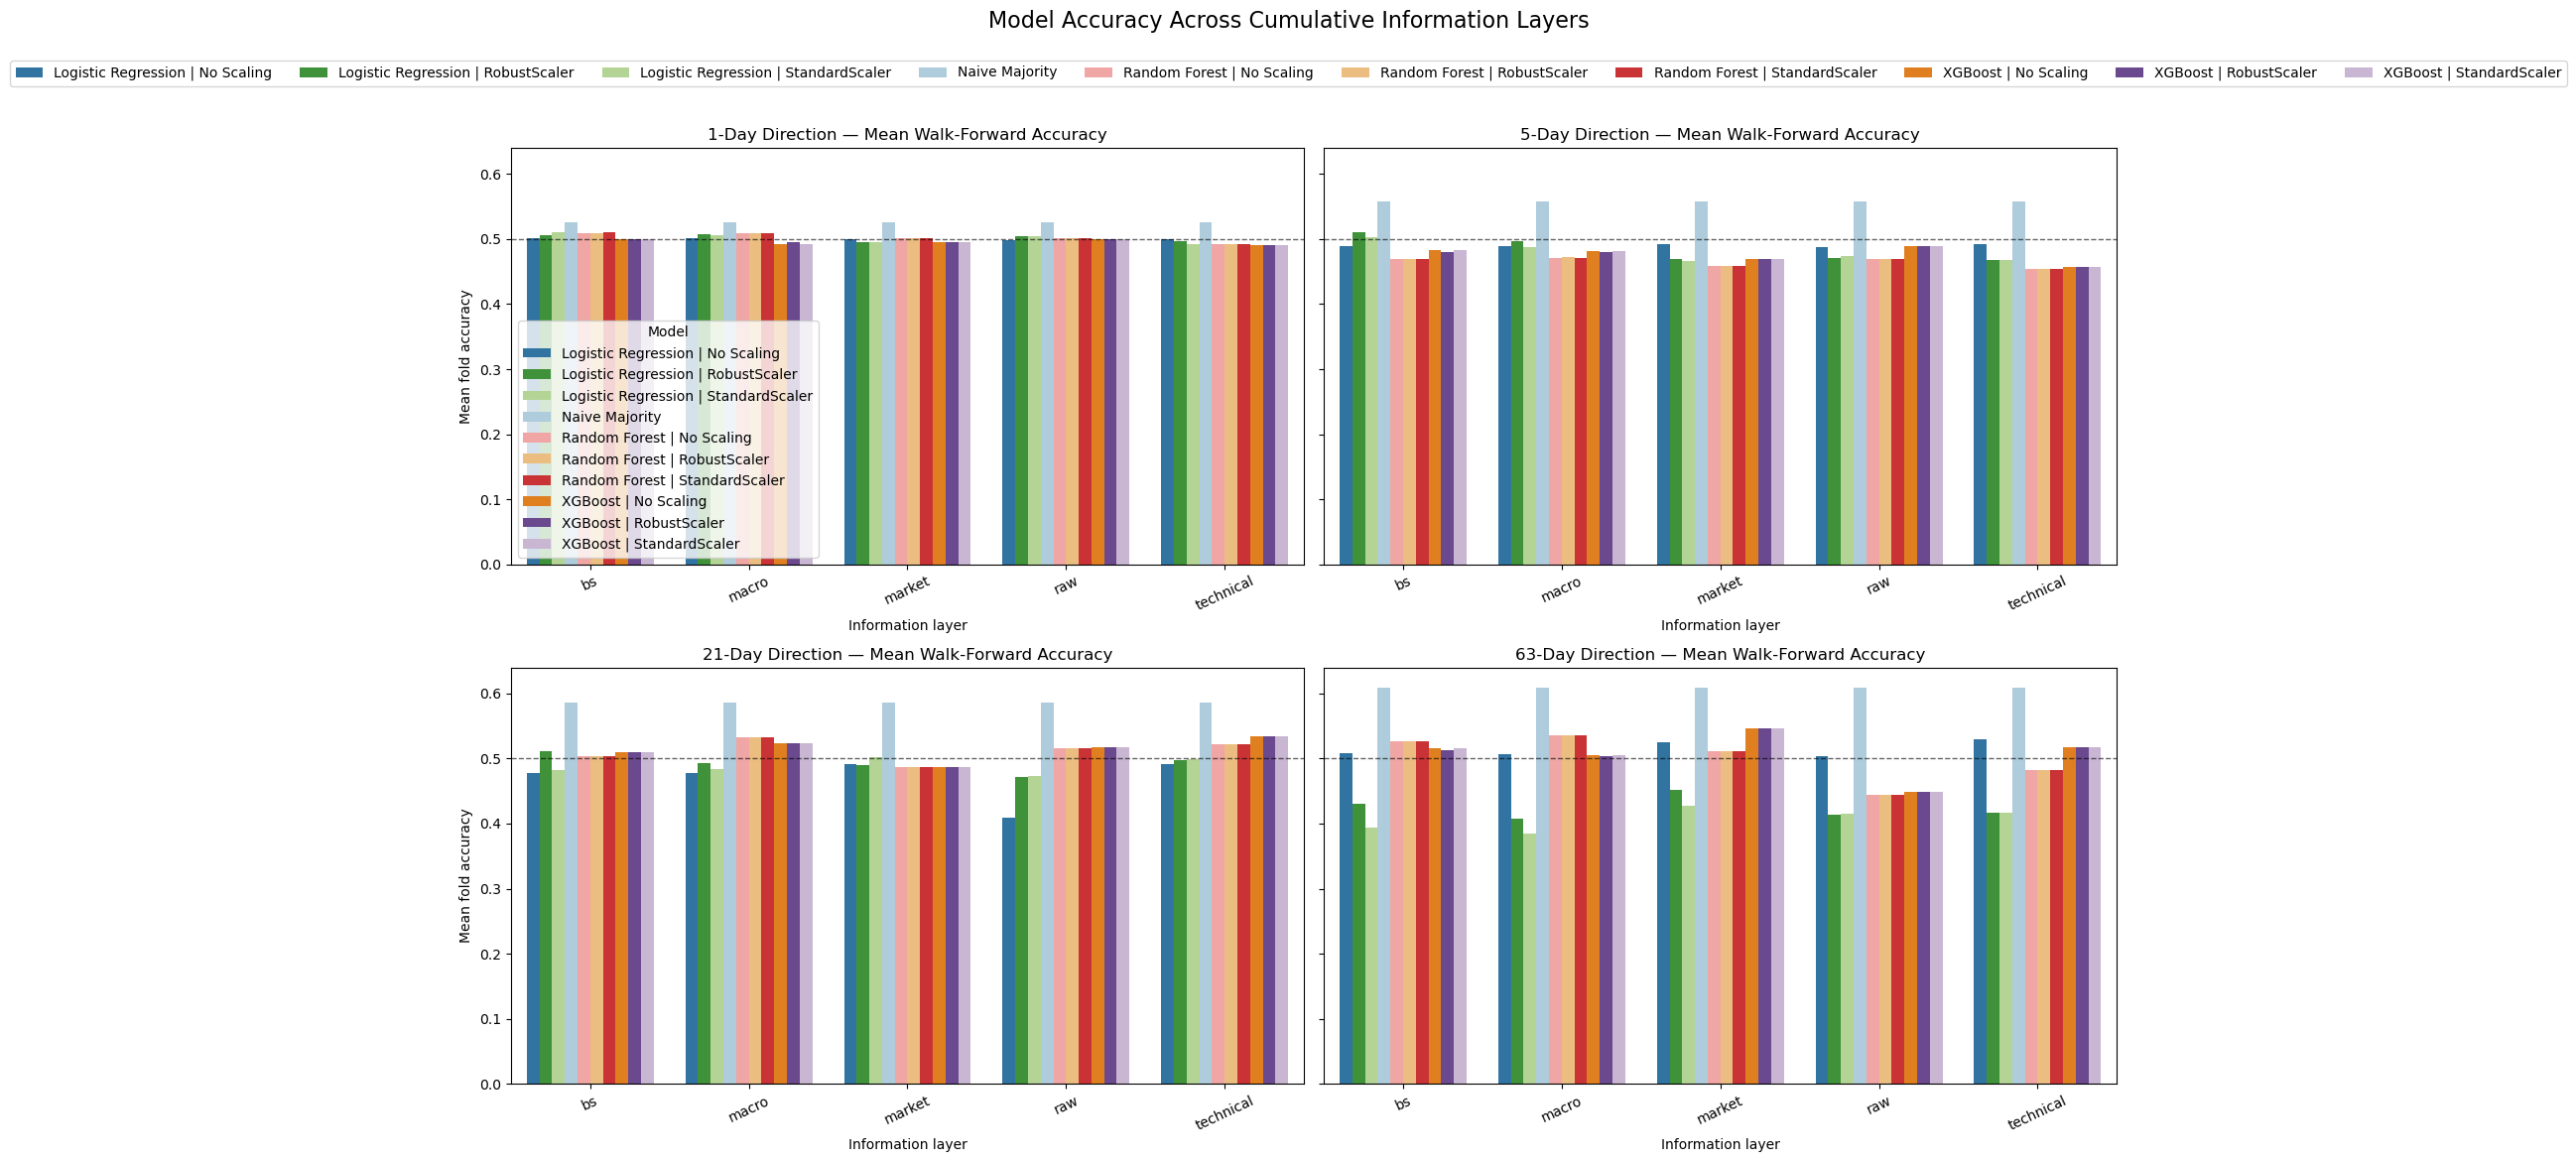

In [138]:
#Give model colors for visualizations
model_names = list(models.keys())
palette = sns.color_palette("Paired", n_colors=len(model_names))
model_colors = dict(zip(model_names, palette))

#Plot accuracy by layer and horizon, separate panel per horizon
fig, axes = plt.subplots(2, 2, figsize=(17, 11), sharey=True)
for ax, h in zip(axes.flat, horizons):
    sub = aggregate_metrics[aggregate_metrics["Horizon"] == h]
    sns.barplot(sub, x="Layer", y="Accuracy_Mean", hue="Model",
    palette=model_colors, ax=ax, errorbar=None)
    ax.set_title(f"{h}-Day Direction — Mean Walk-Forward Accuracy")
    ax.set_xlabel("Information layer")
    ax.set_ylabel("Mean fold accuracy")
    ax.tick_params(axis="x", rotation=25)
    ax.axhline(0.5, color="black", linestyle="--", linewidth=1, alpha=0.6)
    if ax.get_legend() and ax is not axes.flat[0]:
        ax.get_legend().remove()
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=len(labels), bbox_to_anchor=(0.5, 1.02))
fig.suptitle("Model Accuracy Across Cumulative Information Layers", y=1.06, fontsize=16)
plt.tight_layout()
plt.show()

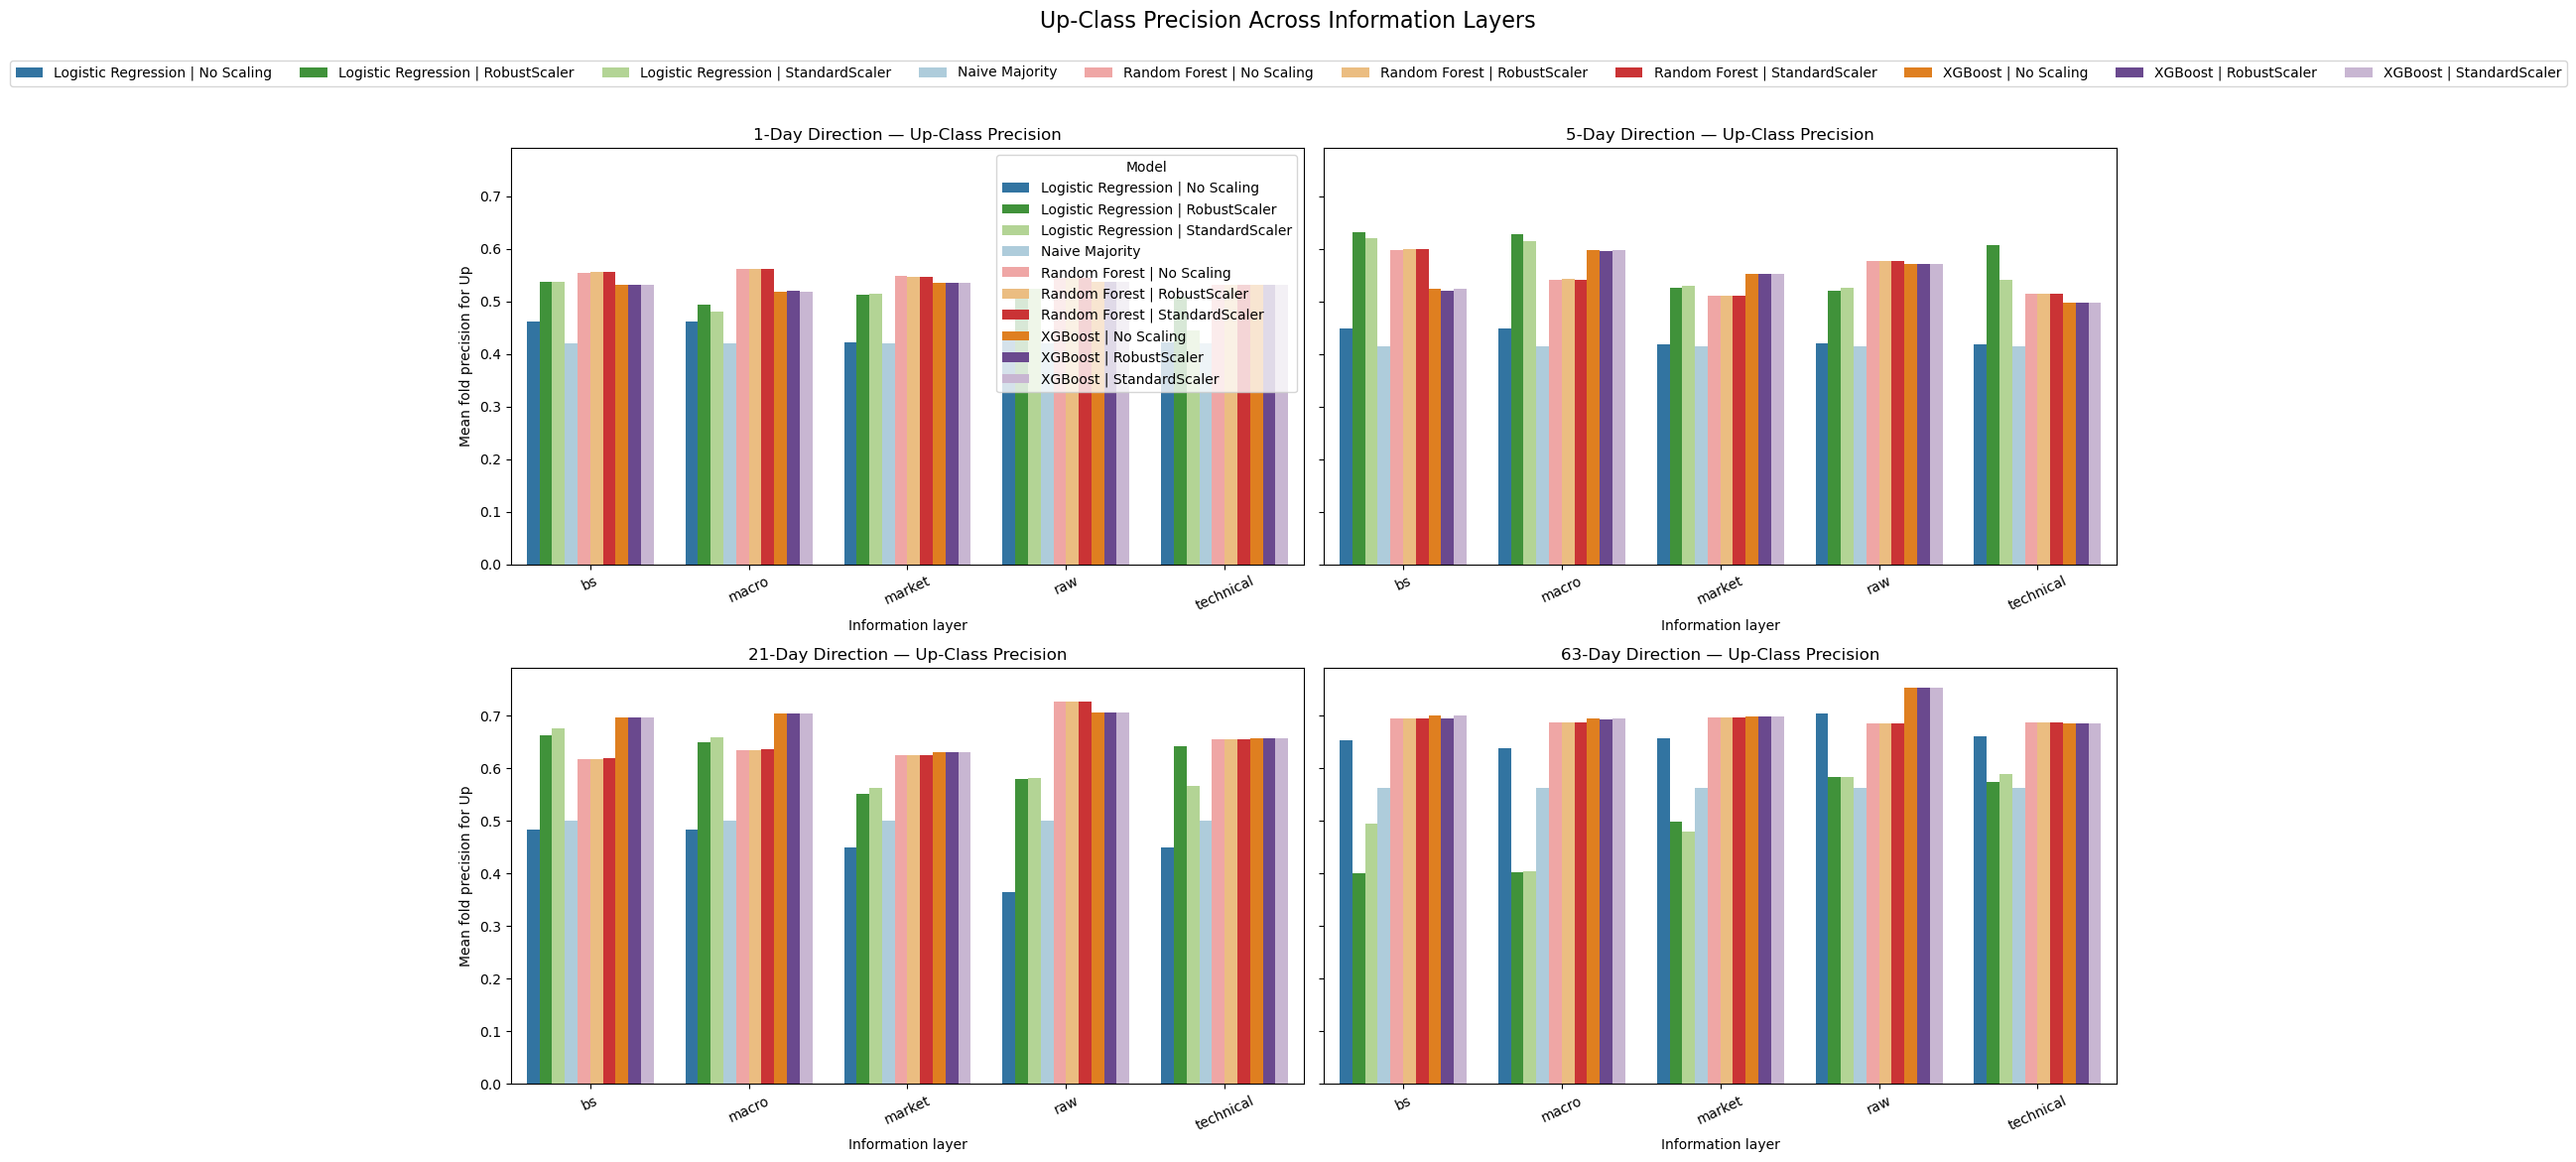

In [140]:
#Plot Up-class precision comparison
fig, axes = plt.subplots(2, 2, figsize=(17, 11), sharey=True)
for ax, h in zip(axes.flat, horizons):
    sub = aggregate_metrics[aggregate_metrics["Horizon"] == h]
    sns.barplot(data=sub, x="Layer", y="Up_Precision_Mean", hue="Model",
        palette=model_colors, ax=ax, errorbar=None)
    ax.set_title(f"{h}-Day Direction — Up-Class Precision")
    ax.set_xlabel("Information layer")
    ax.set_ylabel("Mean fold precision for Up")
    ax.tick_params(axis="x", rotation=25)
    if ax.get_legend() and ax is not axes.flat[0]:
        ax.get_legend().remove()
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=len(labels), bbox_to_anchor=(0.5, 1.02))
fig.suptitle("Up-Class Precision Across Information Layers", y=1.06, fontsize=16)
plt.tight_layout()
plt.show()

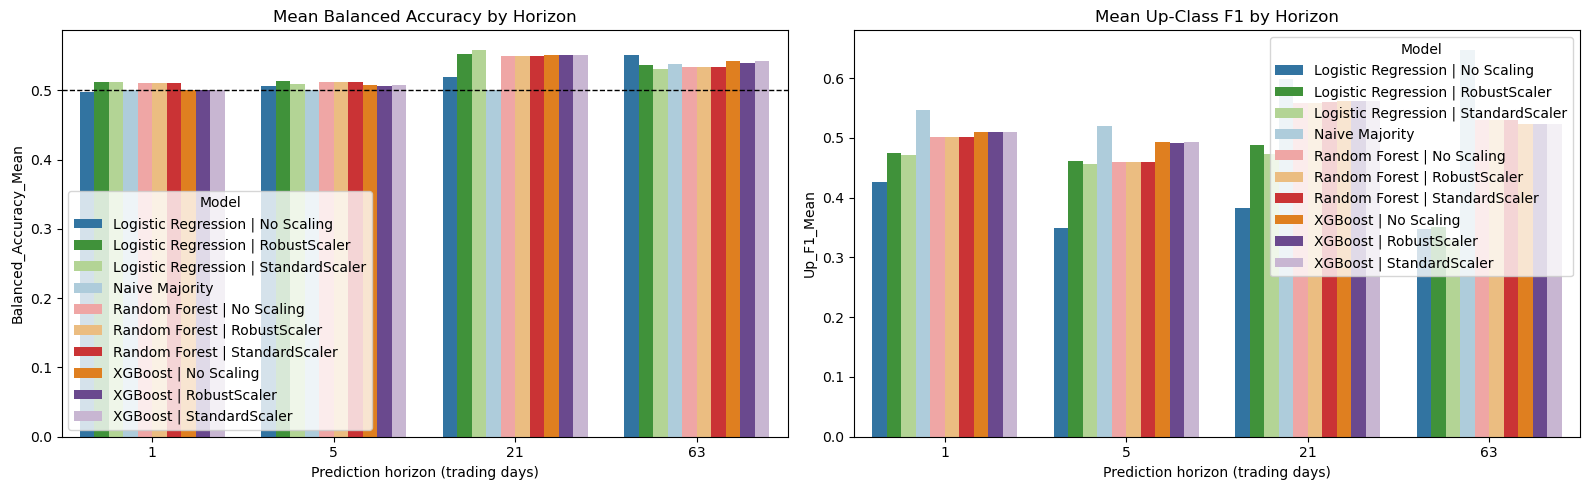

In [142]:
#Plot balanced accuracy and F1
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
#Balanced accuracy
sns.barplot(data=aggregate_metrics, x="Horizon", y="Balanced_Accuracy_Mean", hue="Model",
            palette=model_colors, ax=axes[0], errorbar=None)
axes[0].set_title("Mean Balanced Accuracy by Horizon")
axes[0].axhline(0.5, color="black", linestyle="--", linewidth=1)
#Up F1
sns.barplot(data=aggregate_metrics, x="Horizon", y="Up_F1_Mean", hue="Model",
            palette=model_colors, ax=axes[1], errorbar=None)
axes[1].set_title("Mean Up-Class F1 by Horizon")
for ax in axes:
    ax.set_xlabel("Prediction horizon (trading days)")
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

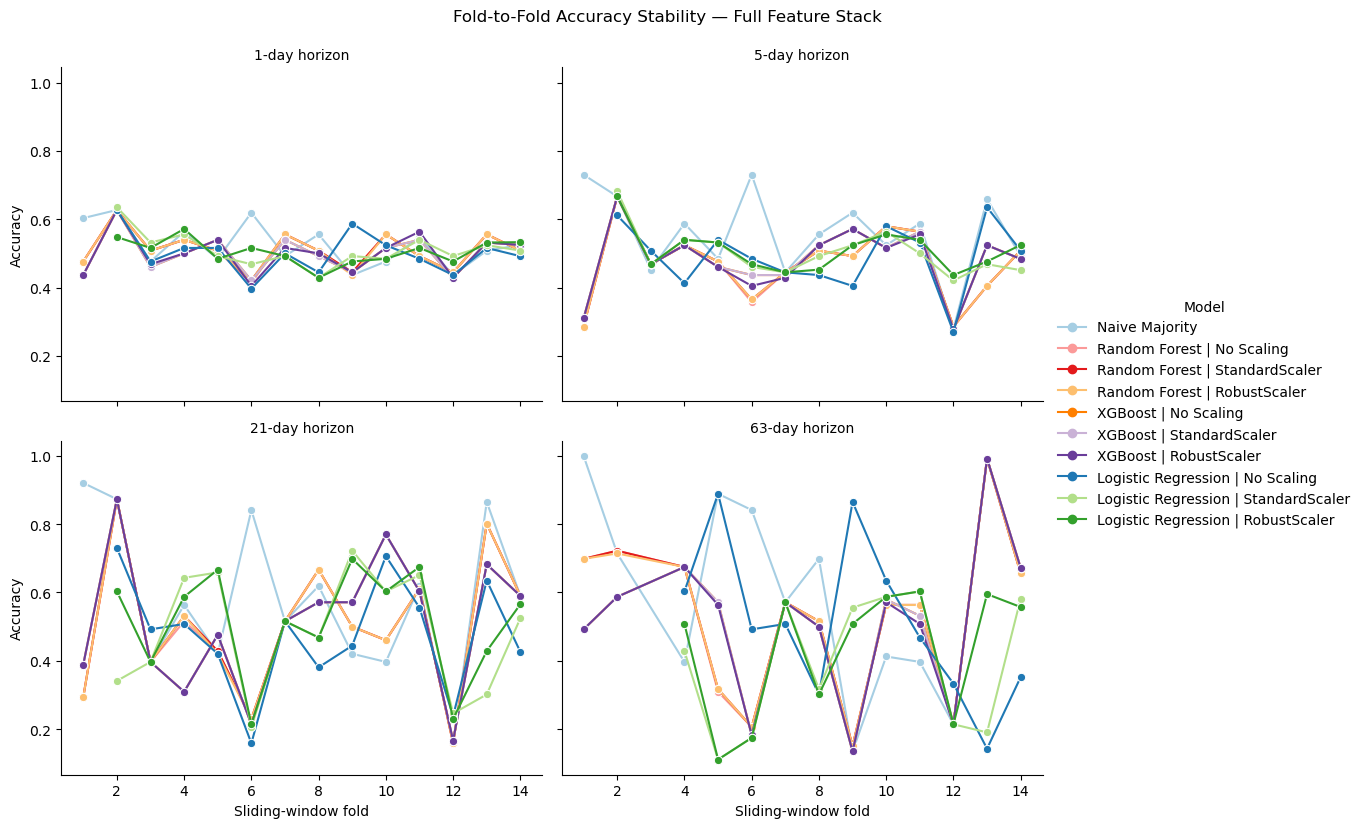

In [154]:
# Fold stability check - show each model's accuracy across folds for full feature 

full_layer = metrics_df[metrics_df["Layer"] == "bs"]
g = sns.relplot(data=full_layer, x="Fold", y="Accuracy", hue="Model", col="Horizon",
    kind="line", marker="o", col_wrap=2, palette=model_colors,
    facet_kws={"sharey": True}, height=4, aspect=1.35)
g.set_axis_labels("Sliding-window fold", "Accuracy")
g.set_titles("{col_name}-day horizon")
g.fig.suptitle("Fold-to-Fold Accuracy Stability — Full Feature Stack", y=1.03)
plt.show()

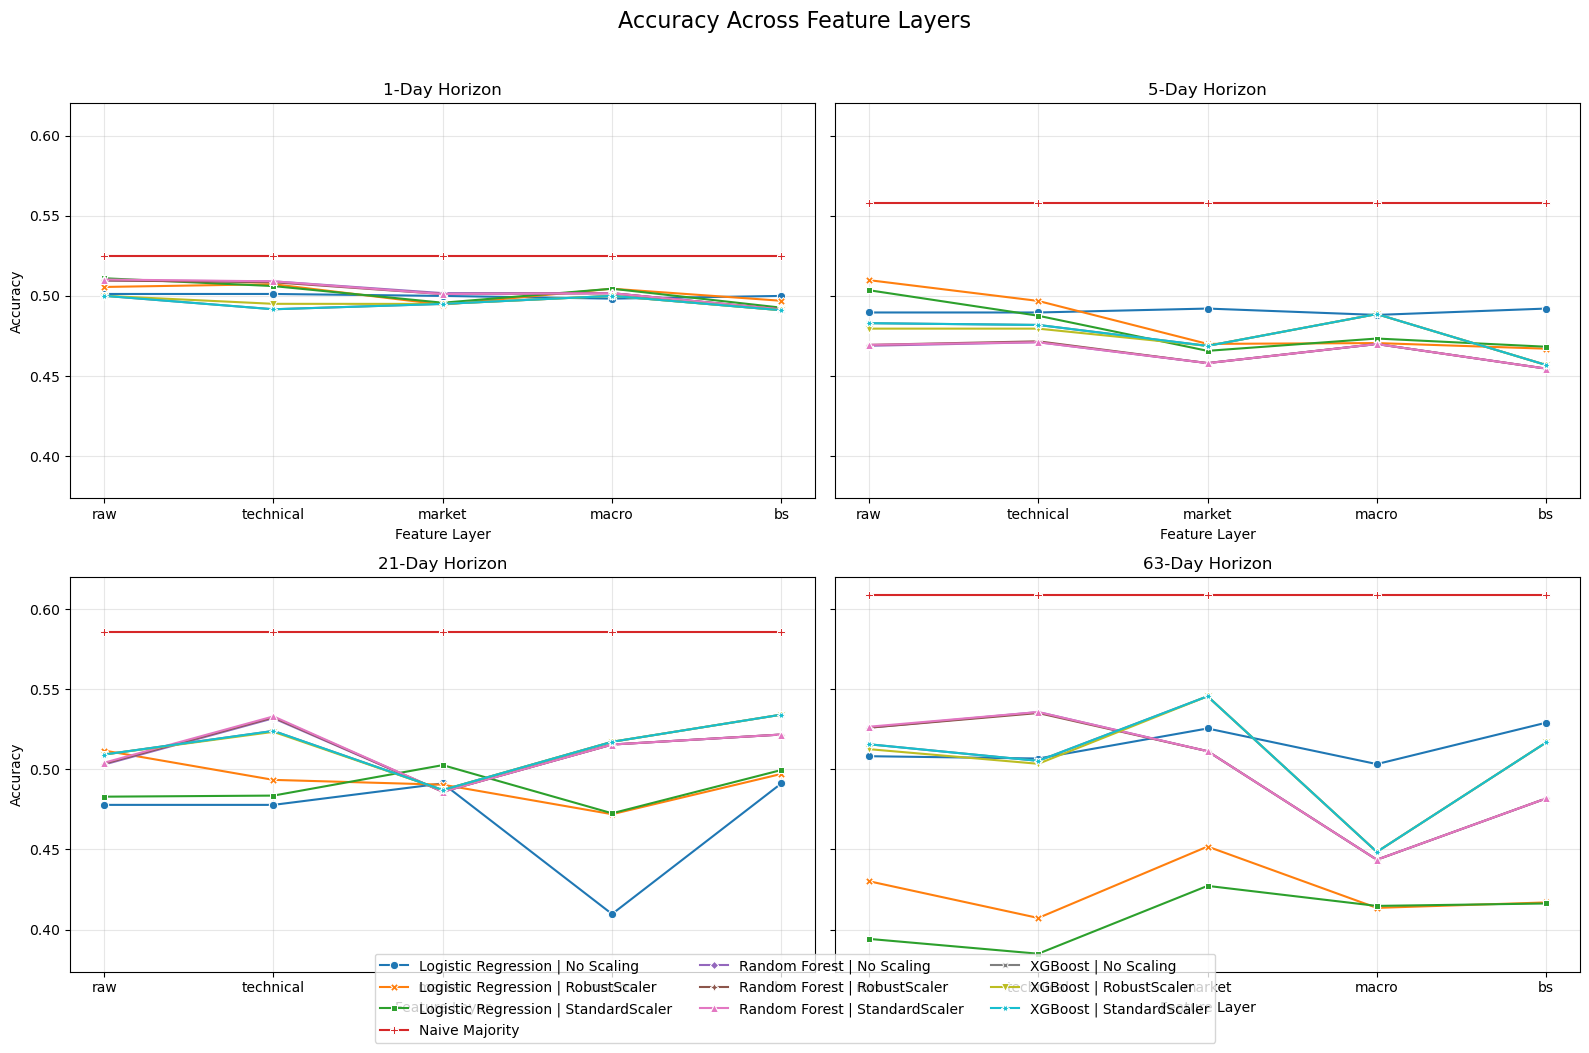

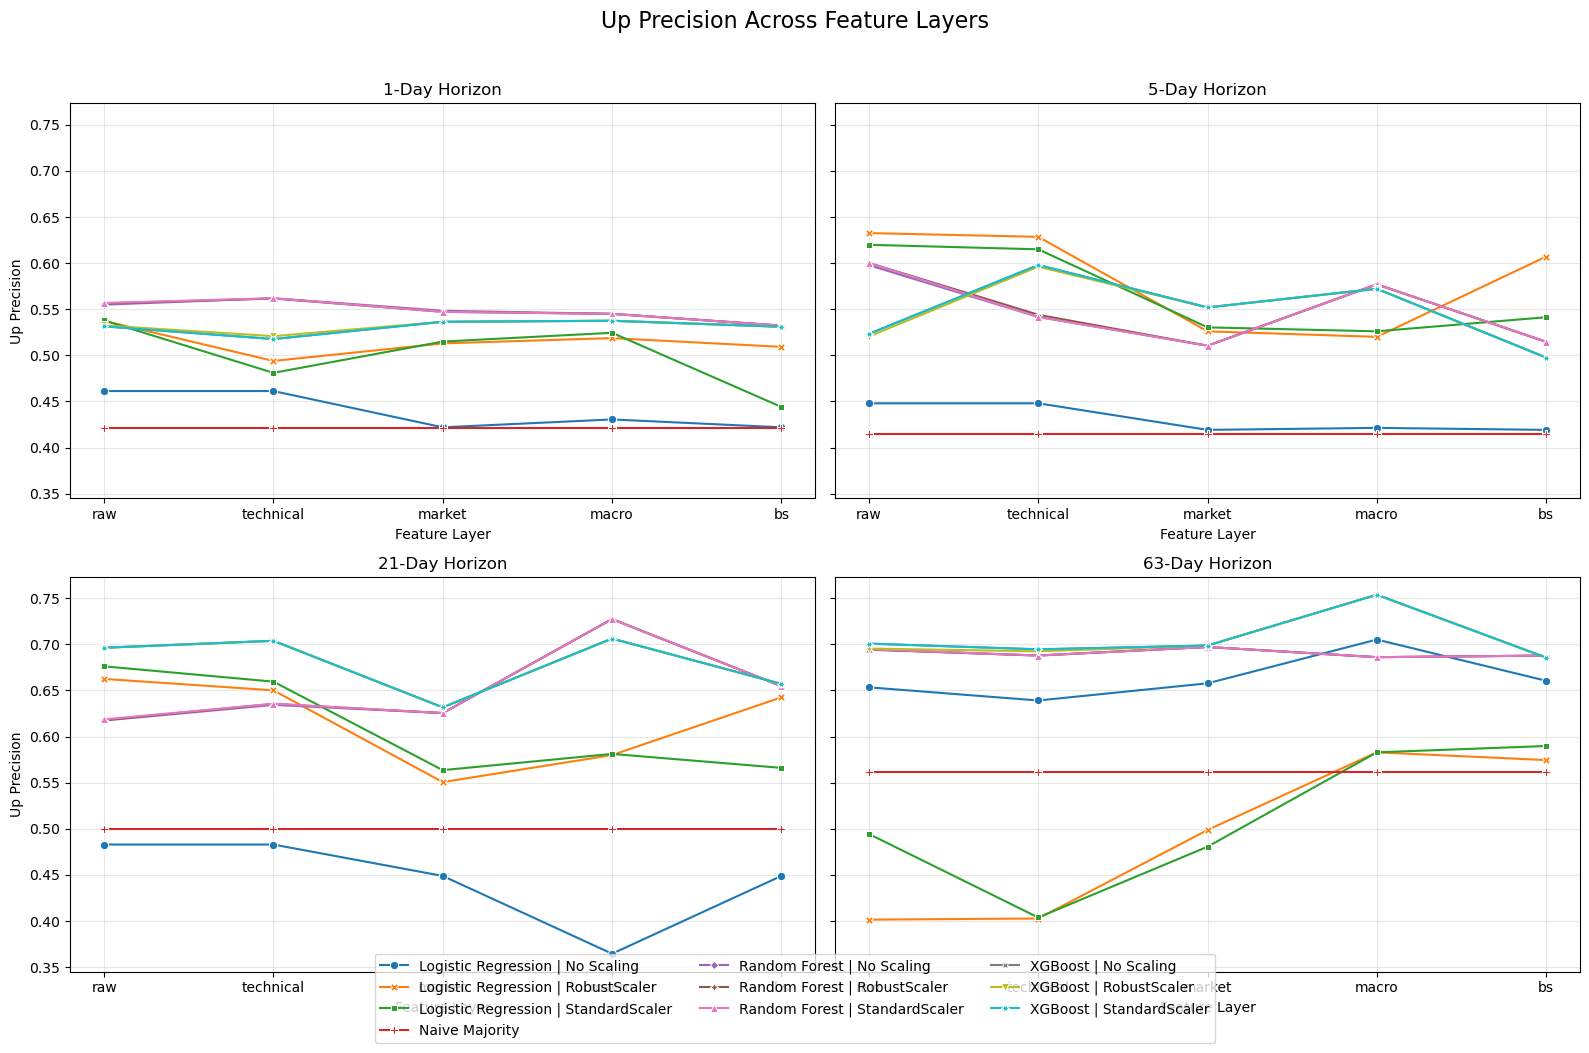

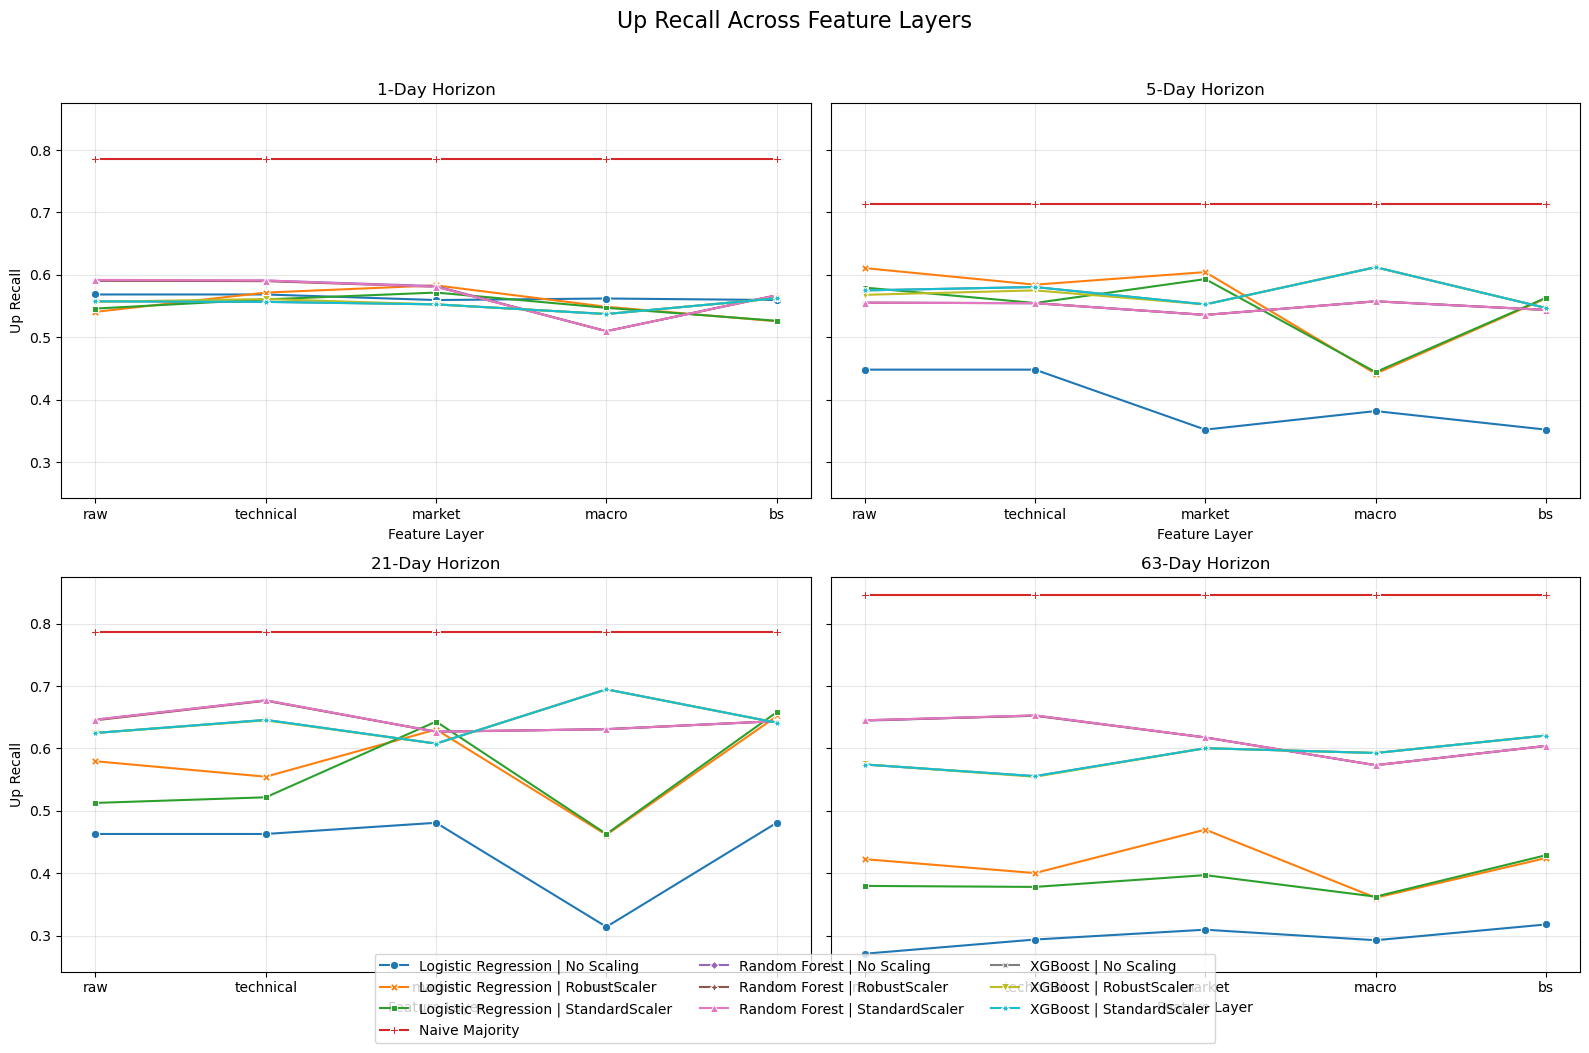

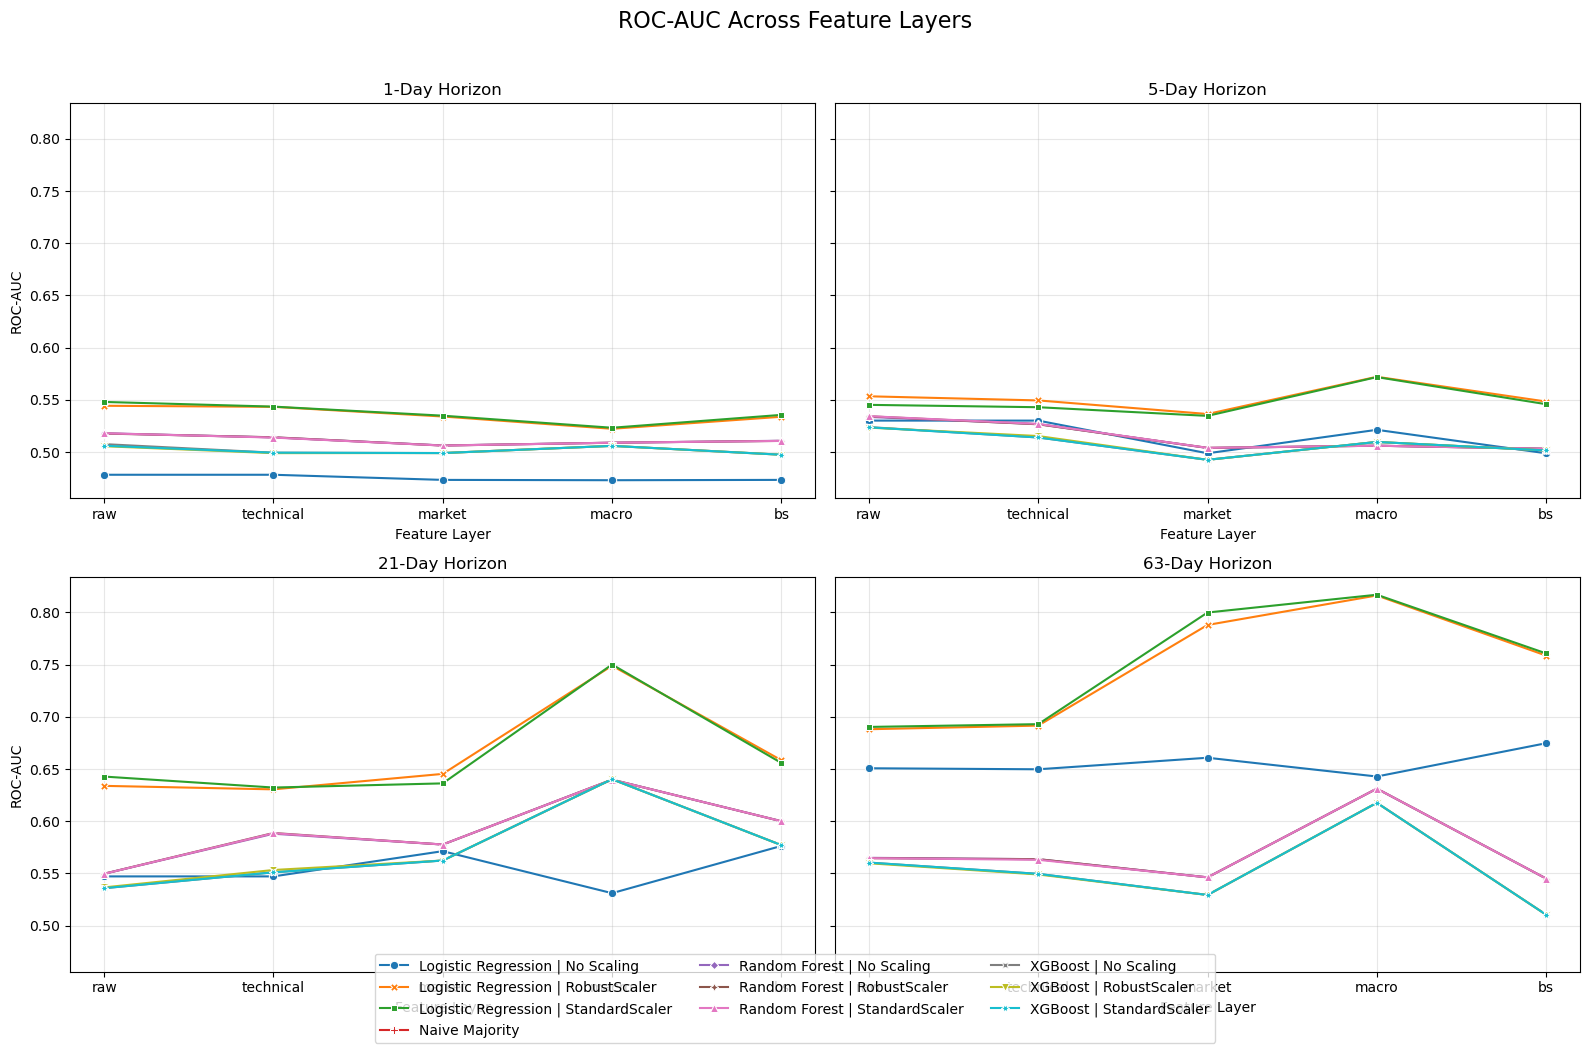

In [172]:
#Plot metric scores over each information layer
metric_names = ["Accuracy", "Up_Precision", "Up_Recall", "ROC_AUC"]

metric_titles = {"Accuracy": "Accuracy",
                 "Up_Precision": "Up Precision",
                 "Up_Recall": "Up Recall",
                 "ROC_AUC": "ROC-AUC"}

for metric in metric_names:
    fig, axes = plt.subplots(2, 2, figsize=(16, 10), sharey=True)

    axes = axes.flatten()

    for ax, h in zip(axes, horizon_order):
        plot_data = (metrics_df[metrics_df["Horizon"] == h].groupby(["Layer", "Model"])[metric]
            .mean().reset_index())

        sns.lineplot(data=plot_data, x="Layer", y=metric, hue="Model", style="Model",
                     markers=True, dashes=False, sort=False, ax=ax)

        ax.set_title(f"{h}-Day Horizon")
        ax.set_xlabel("Feature Layer")
        ax.set_ylabel(metric_titles[metric])
        ax.set_xticks(range(len(layer_order)))
        ax.set_xticklabels(layer_order)
        ax.grid(alpha=0.3)

        if ax.legend_:
            ax.legend_.remove()

    handles, labels = axes[0].get_legend_handles_labels()

    fig.legend(handles, labels,loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.02))

    fig.suptitle(f"{metric_titles[metric]} Across Feature Layers",fontsize=16, y=1.02)
    plt.tight_layout()
    plt.show()

# Mutual Information & Feature Importance

In [177]:
#Mutual Information calculated inside train folds

mi_rows = []

for layer_name, features in feature_sets.items():
    df = datasets[layer_name]

    for h in horizons:
        target_col = f"direction_{h}d"
        label_end_col = f"label_end_{h}d"

        for _, fold in folds_df.iterrows():
            fold_start = fold["Test_Start"]

            train_df = df[(df["Date"] >= fold["Train_Start"]) &
            (df["Date"] <= fold["Train_End"]) &
            (df[label_end_col].notna()) &
            (df[label_end_col] < fold_start) &
            (df[target_col].notna())].copy()
            
            #data length safeguard
            if len(train_df) < 150:
                continue

            y = train_df[target_col].astype(int)

            if y.nunique() < 2:
                continue

            for feature in features:
                valid = (train_df[feature].notna() & np.isfinite(train_df[feature]))

                X_feature = train_df.loc[valid, [feature]]
                y_feature = y.loc[valid]
                
                #safeguard for data length
                if len(X_feature) < 150 or y_feature.nunique() < 2:
                    continue
                if X_feature[feature].nunique() < 2:
                    continue
                    
                #Actual MI part
                mi_score = mutual_info_classif(X_feature,y_feature, discrete_features=False,
                    random_state=42)[0]

                mi_rows.append({"Layer": layer_name,
                                "Horizon": h,
                                "Fold": fold["Fold"],
                                "Feature": feature,
                                "MI": mi_score,
                                "N_Used": len(X_feature)})

mi_df = pd.DataFrame(mi_rows)
print(mi_df.shape)
mi_df.head()

(7707, 6)


,Layer,Horizon,Fold,Feature,MI,N_Used
0,raw,1,1,Open,0.055247,251
1,raw,1,1,High,0.007623,251
2,raw,1,1,Low,0.000000,251
3,raw,1,1,Adj_Close,0.000000,251
4,raw,1,1,Volume,0.038502,251


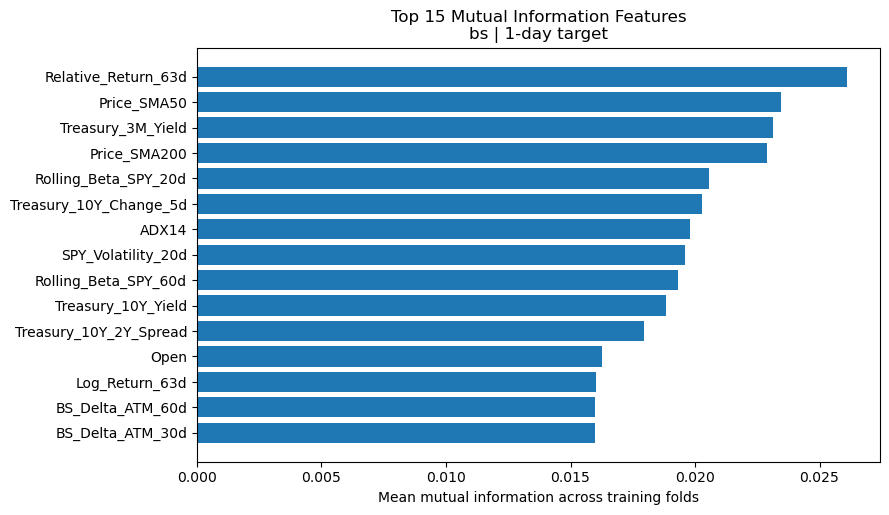

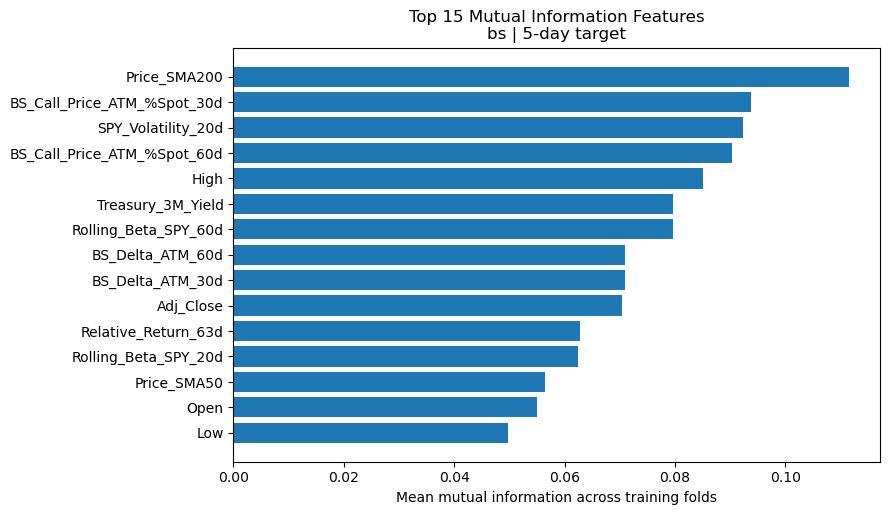

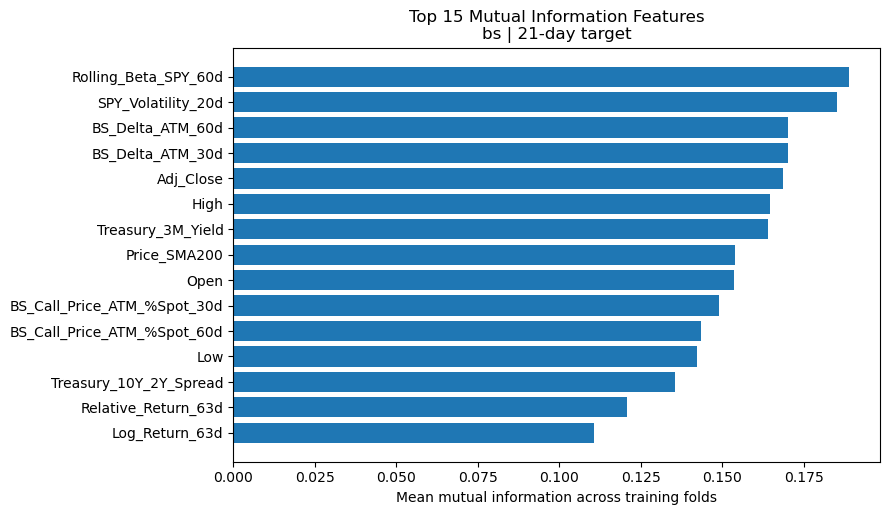

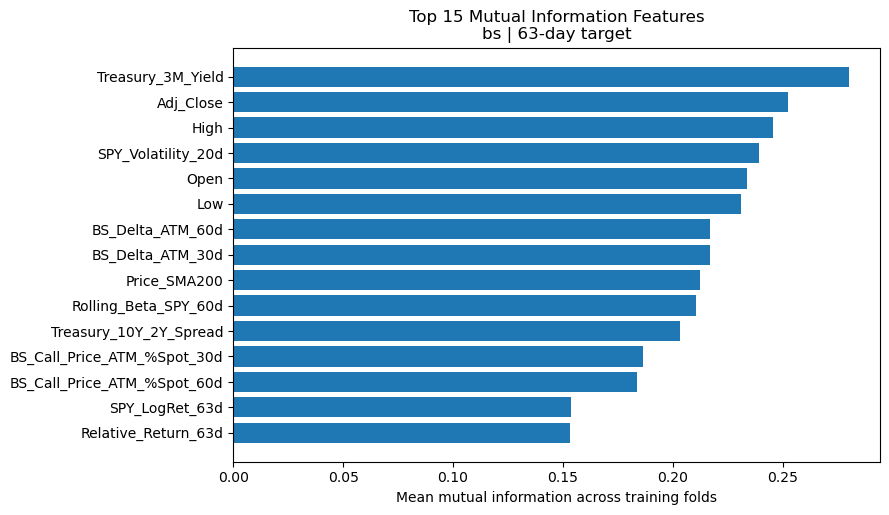

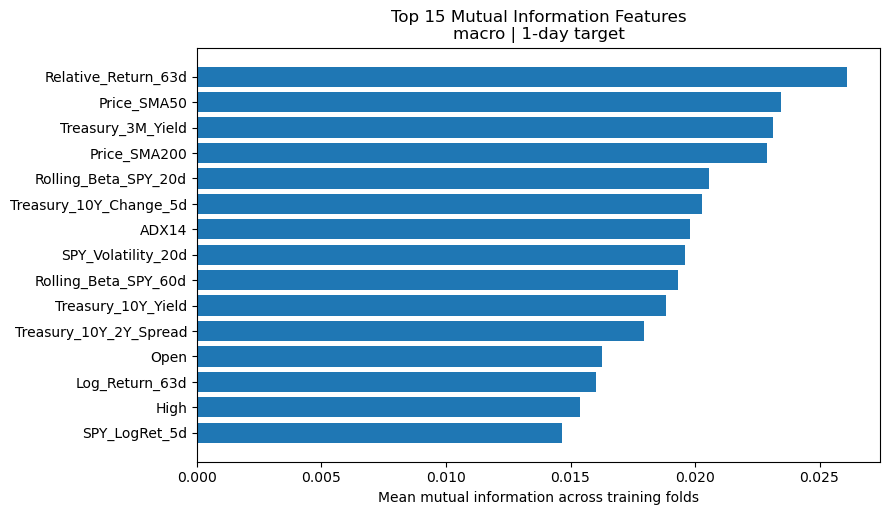

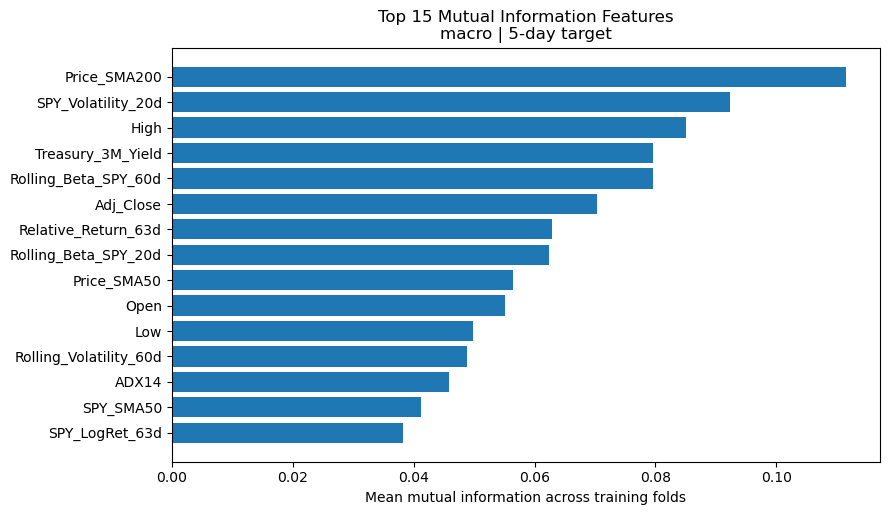

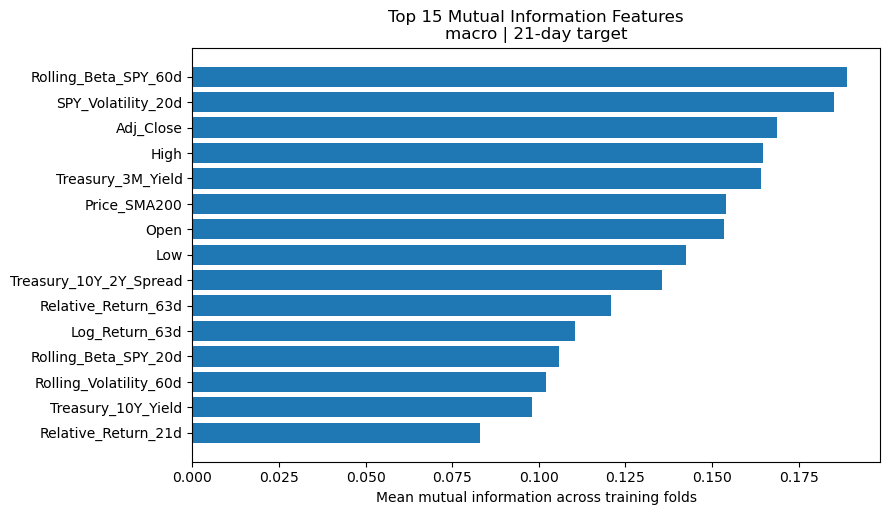

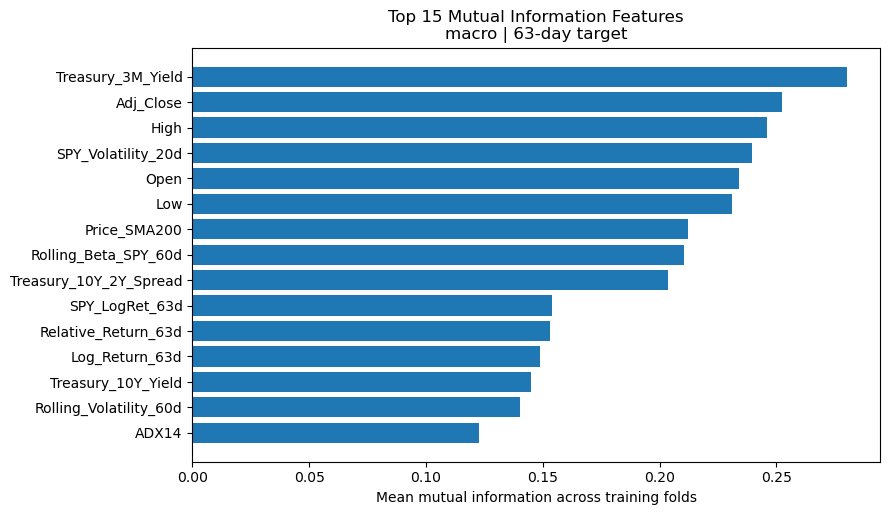

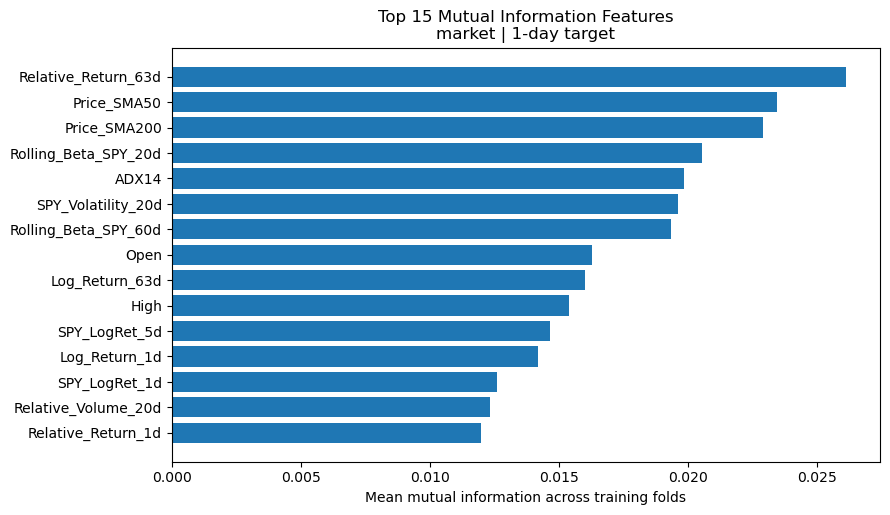

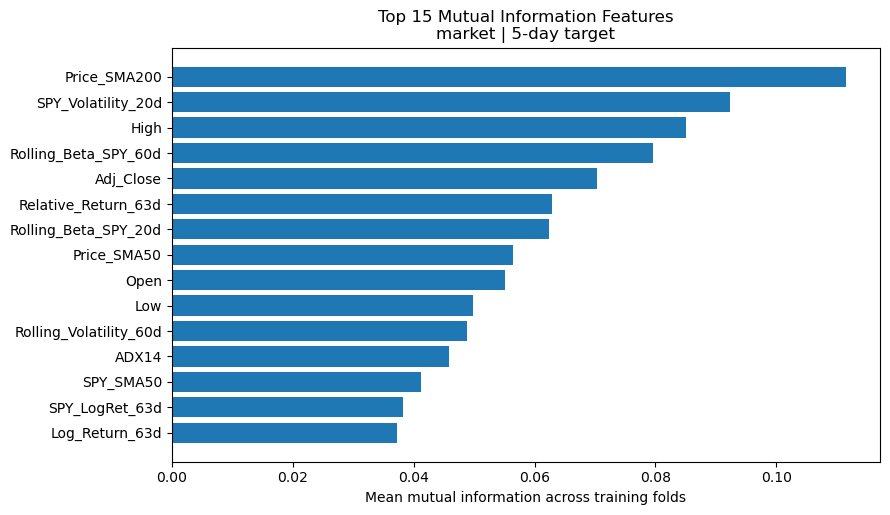

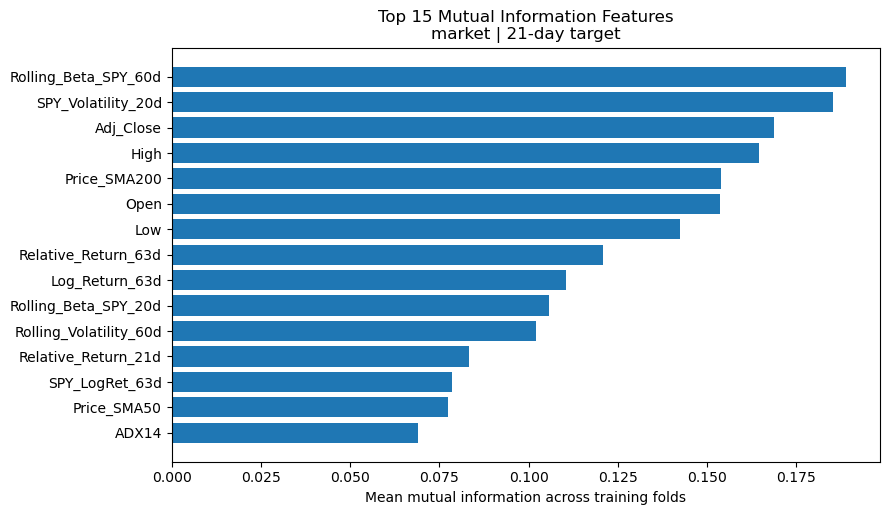

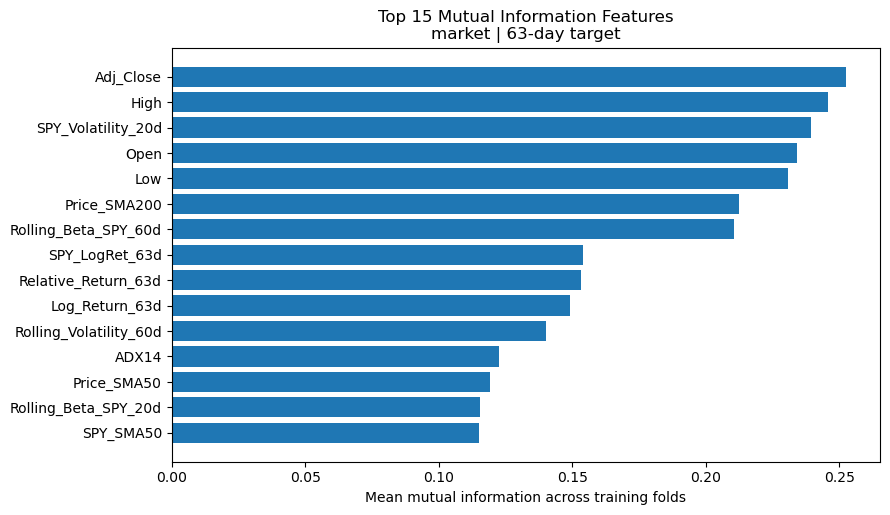

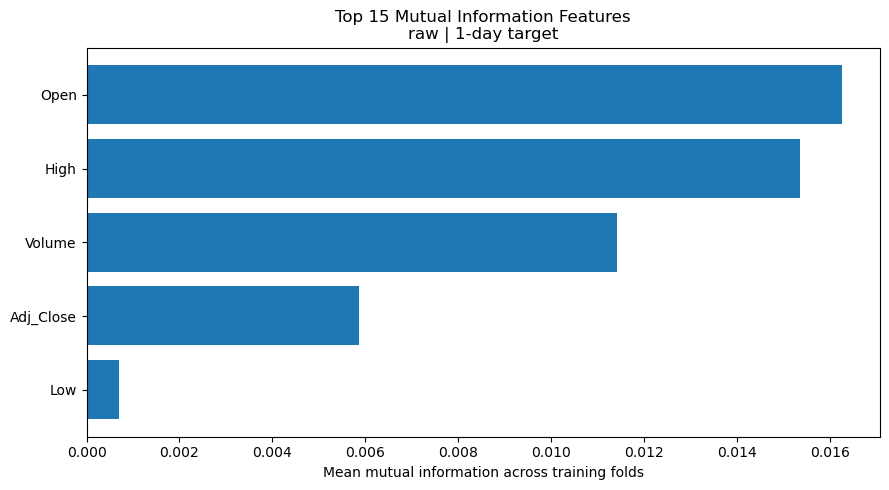

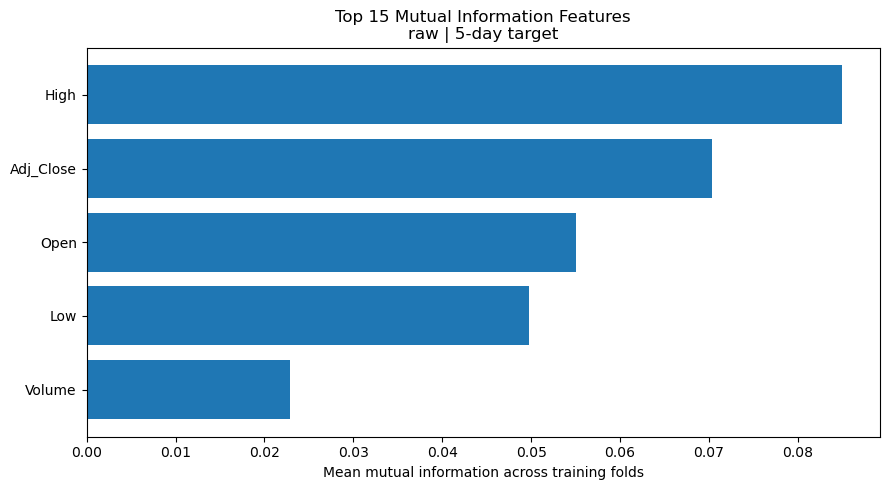

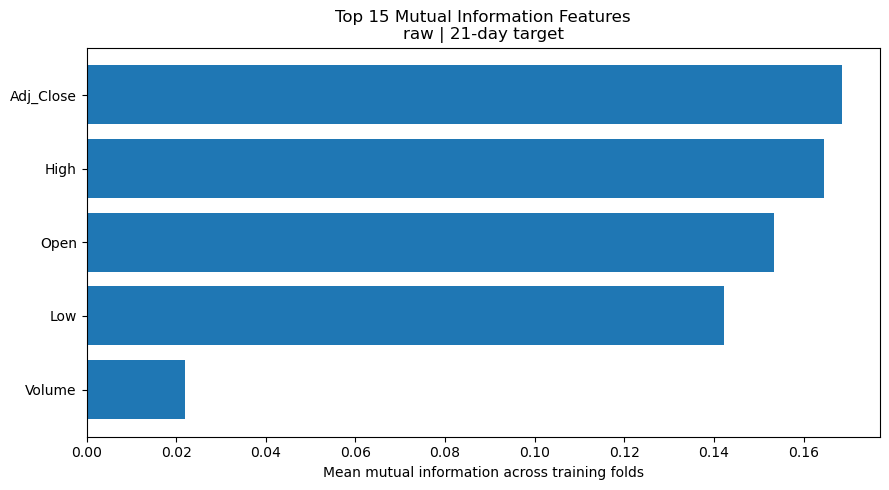

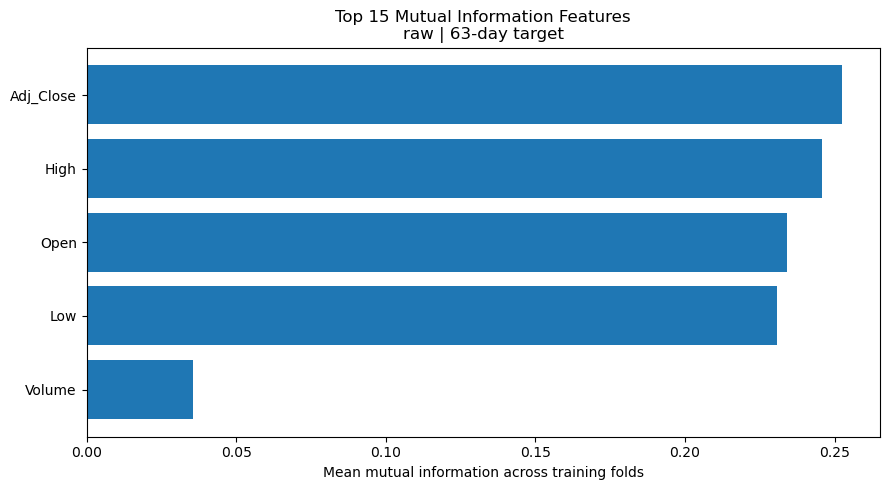

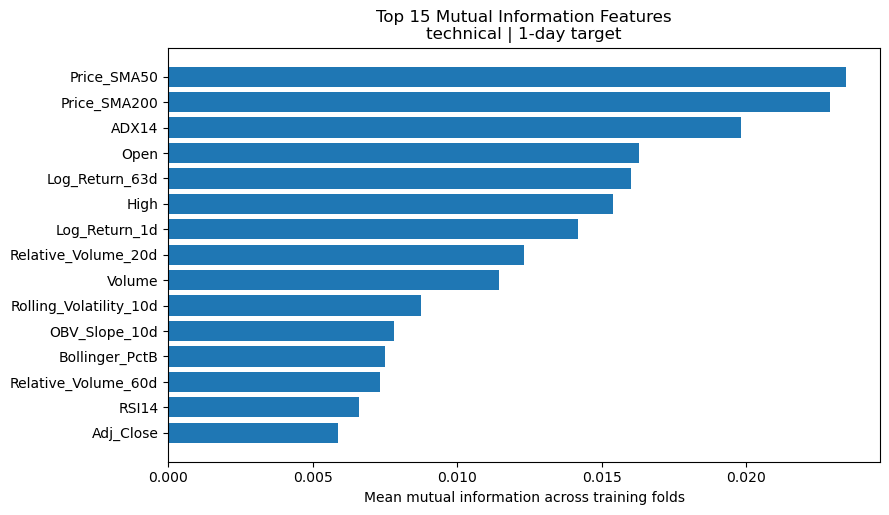

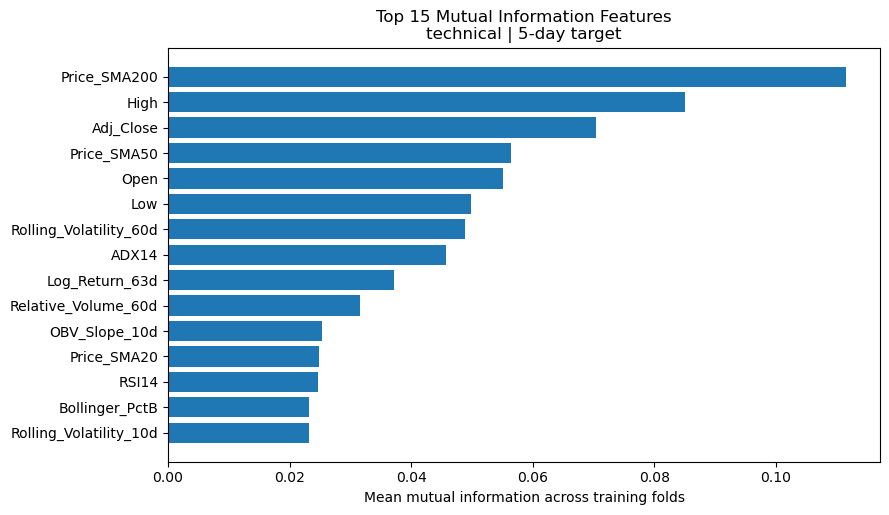

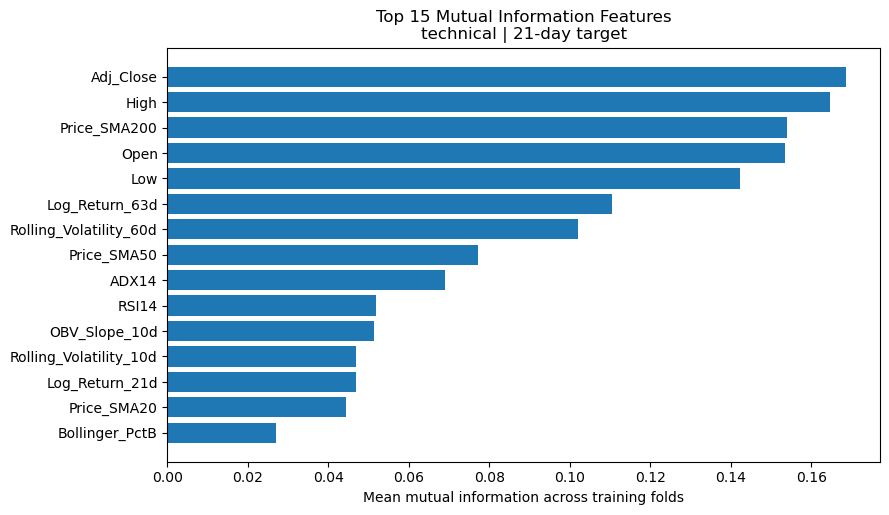

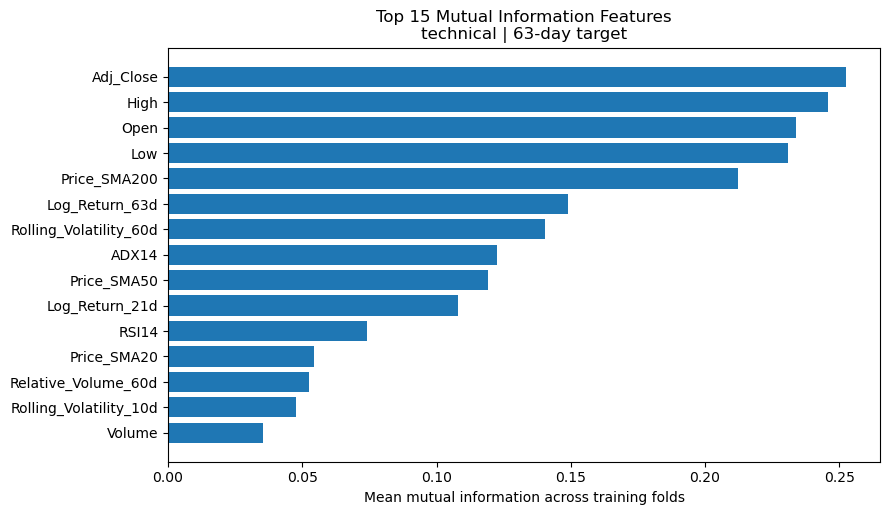

In [183]:
#Plot top MI
for layer_name in mi_summary["Layer"].unique():
    for horizon in horizons:
        plot_df = (mi_summary[(mi_summary["Layer"] == layer_name)
                   & (mi_summary["Horizon"] == horizon)].nlargest(15, "Mean_MI")
                   .sort_values("Mean_MI"))

        if plot_df.empty:
            continue

        plt.figure(figsize=(9, max(5, len(plot_df) * 0.35)))
        plt.barh(plot_df["Feature"], plot_df["Mean_MI"])
        plt.title(f"Top 15 Mutual Information Features\n"
                  f"{layer_name} | {horizon}-day target")
        plt.xlabel("Mean mutual information across training folds")
        plt.ylabel("")
        plt.tight_layout()
        plt.show()

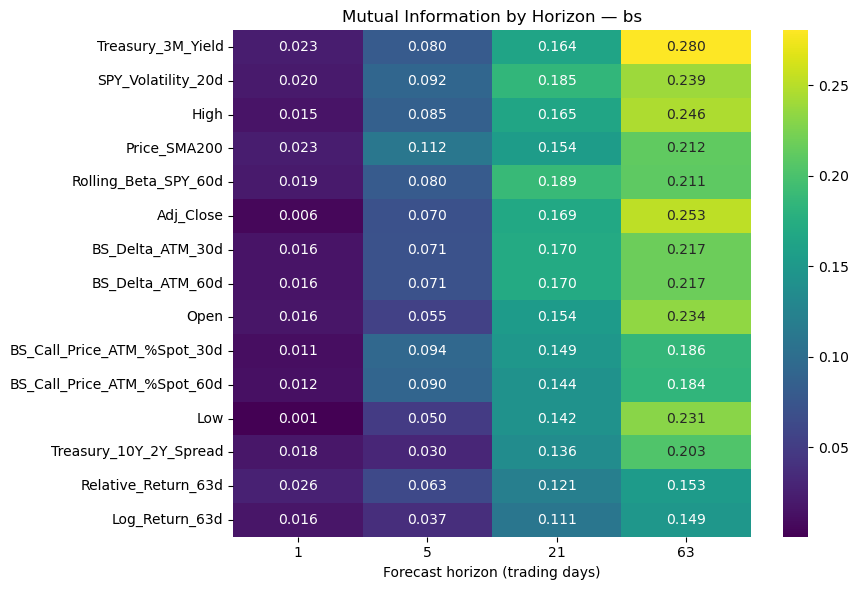

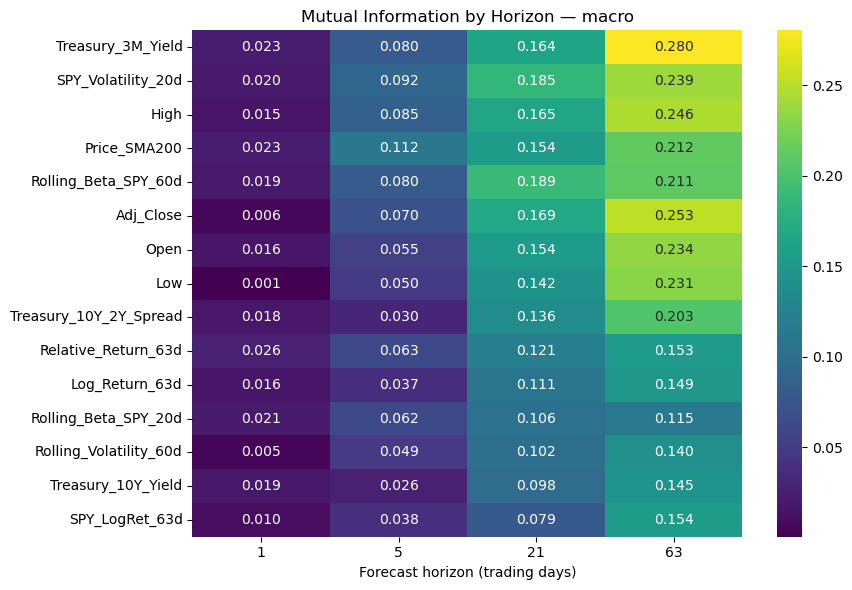

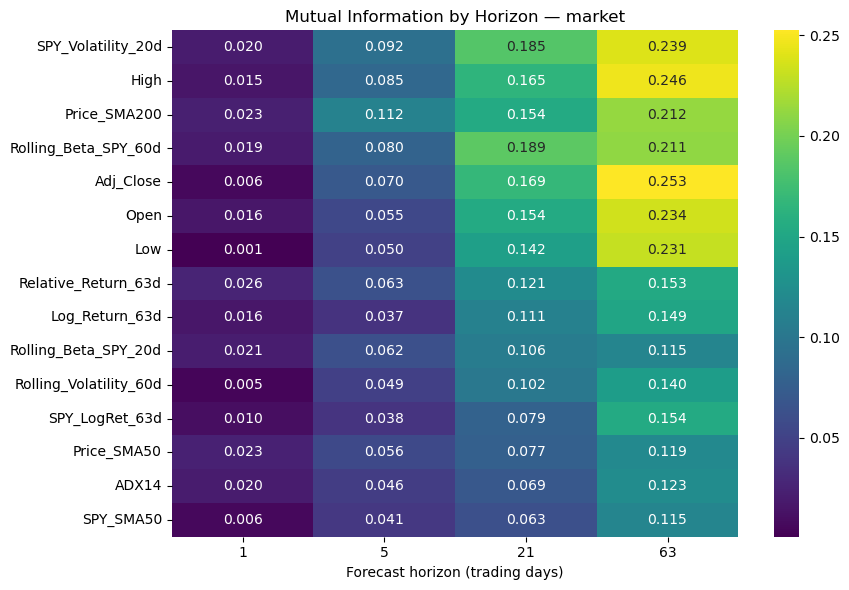

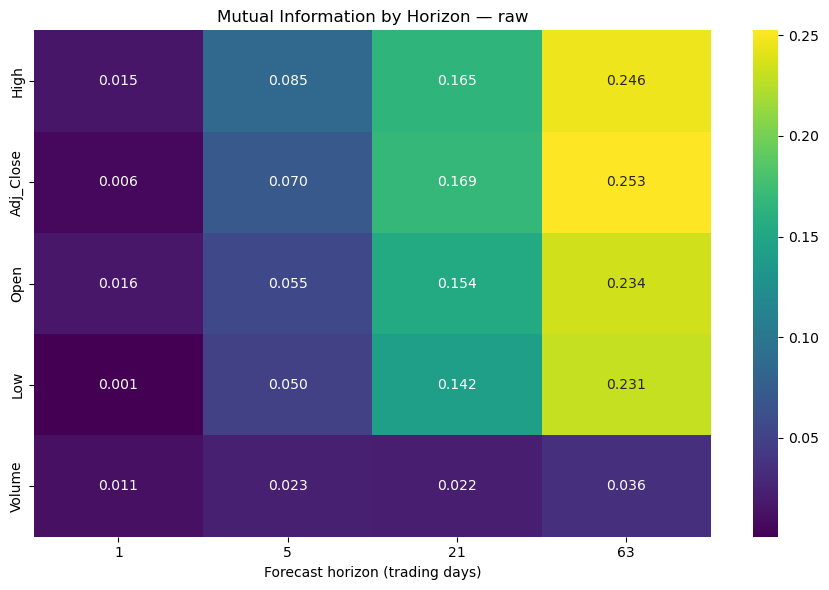

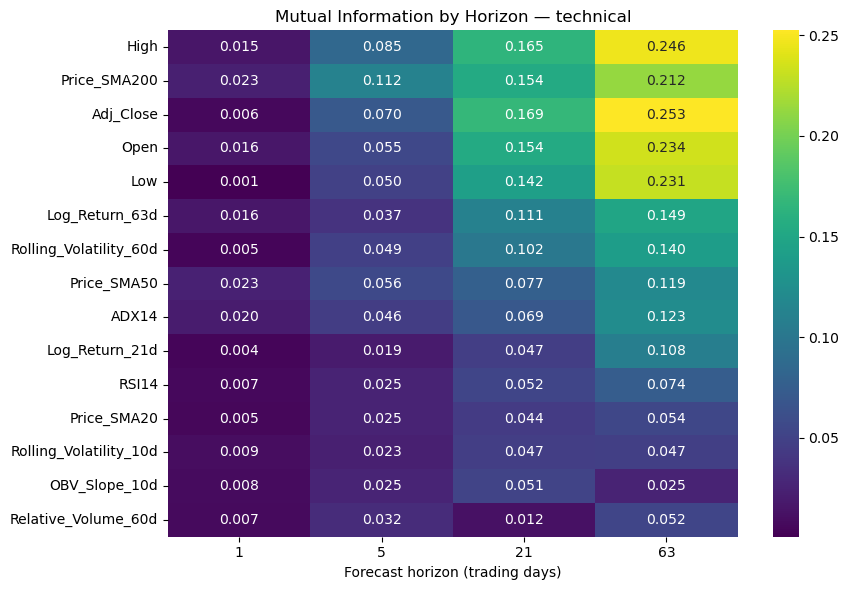

In [181]:
#Compare Mutual Informaion across horizons w heatmap

for layer_name in mi_summary["Layer"].unique():
    heatmap_df = mi_summary[mi_summary["Layer"] == layer_name]

    pivot = heatmap_df.pivot(index="Feature", columns="Horizon", values="Mean_MI")

    # Show features with the highest average MI across horizons
    top_features = (pivot.mean(axis=1).nlargest(15).index)

    plt.figure(figsize=(9, max(6, len(top_features) * 0.35)))
    sns.heatmap(pivot.loc[top_features], annot=True,fmt=".3f",cmap="viridis")
    plt.title(f"Mutual Information by Horizon — {layer_name}")
    plt.xlabel("Forecast horizon (trading days)")
    plt.ylabel("")
    plt.tight_layout()
    plt.show()

In [191]:
#Feature importance with XGBoost

xgb_importance_rows = []

for layer_name, features in feature_sets.items():
    df = datasets[layer_name]

    for h in horizons:
        target_col = f"direction_{h}d"
        label_end_col = f"label_end_{h}d"

        for _, fold in folds_df.iterrows():

            fold_start = fold["Test_Start"]

            train_df = df[(df["Date"] >= fold["Train_Start"]) &
            (df["Date"] <= fold["Train_End"]) &
            (df[label_end_col].notna()) &
            (df[label_end_col] < fold_start) &
            (df[target_col].notna())].copy()

            if len(train_df) < 150:
                continue

            X_train = train_df[features]
            y_train = train_df[target_col].astype(int)

            if y_train.nunique() < 2:
                continue

            model = XGBClassifier(n_estimators=300,max_depth=4,learning_rate=0.05,
                subsample=0.8,colsample_bytree=0.8,objective="binary:logistic",
                eval_metric="logloss",n_jobs=-1,random_state=42,importance_type="gain"
            )

            model.fit(X_train, y_train)

            importances = model.feature_importances_

            for feature, importance in zip(features, importances):

                xgb_importance_rows.append({"Layer": layer_name,
                                            "Horizon": h,
                                            "Fold": fold["Fold"],
                                            "Feature": feature,
                                            "Importance": importance })

xgb_importance_df = pd.DataFrame(xgb_importance_rows)

In [192]:
#Average XGBoost importance across folds
xgb_importance_summary = (xgb_importance_df.groupby(["Layer", "Horizon", "Feature"])
                          .agg(Mean_Importance=("Importance", "mean"),
                               Std_Importance=("Importance", "std"),
                               Folds=("Fold", "nunique")).reset_index())

xgb_importance_summary.head()

,Layer,Horizon,Feature,Mean_Importance,Std_Importance,Folds
0,bs,1,ADX14,0.023445,0.003377,14
1,bs,1,Adj_Close,0.027376,0.007093,14
2,bs,1,BS_Call_Price_ATM_%Spot_30d,0.022993,0.006019,14
3,bs,1,BS_Call_Price_ATM_%Spot_60d,0.024644,0.016399,14
4,bs,1,BS_Delta_ATM_30d,0.020979,0.003705,14


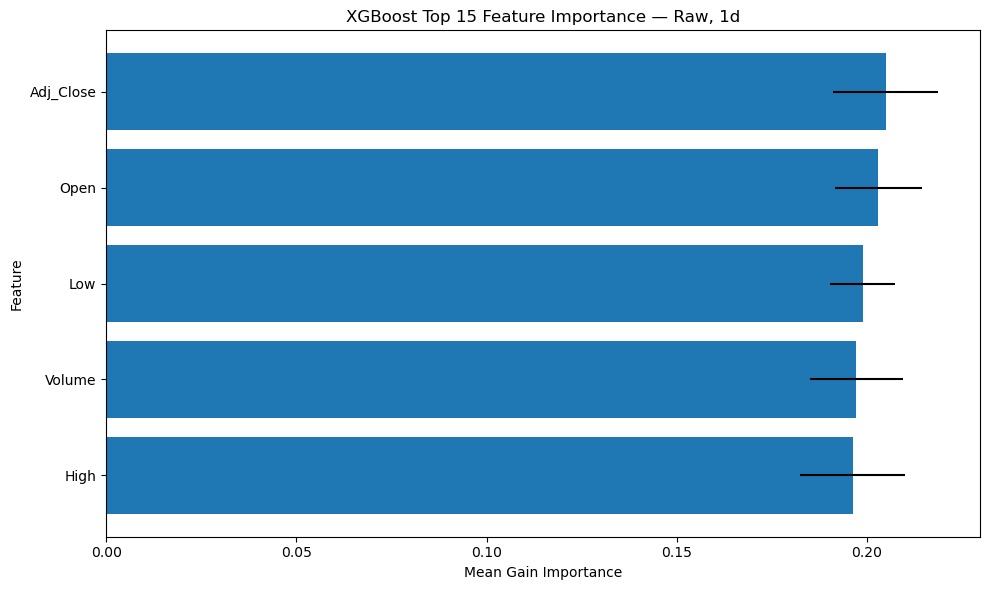

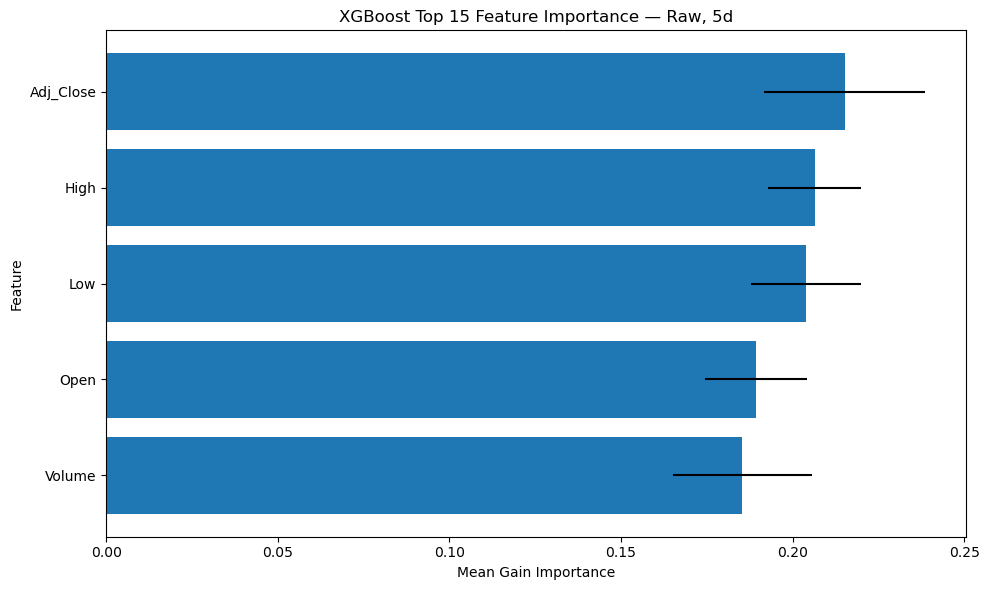

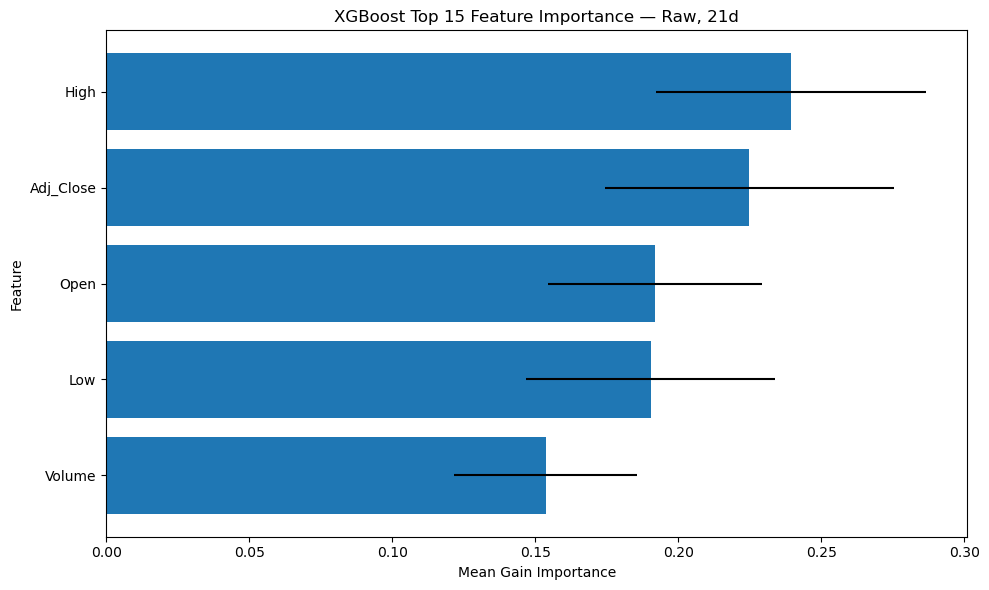

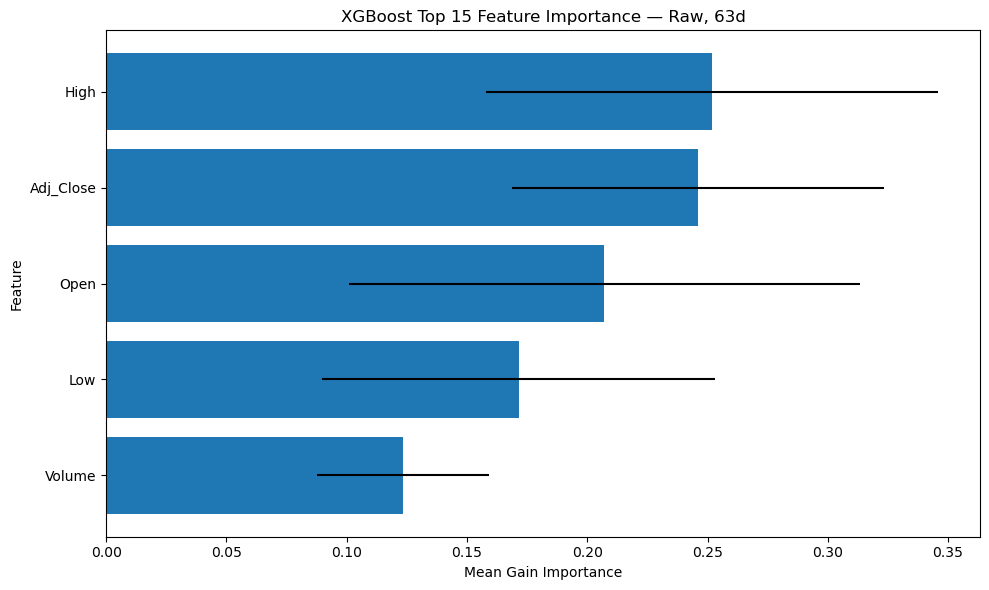

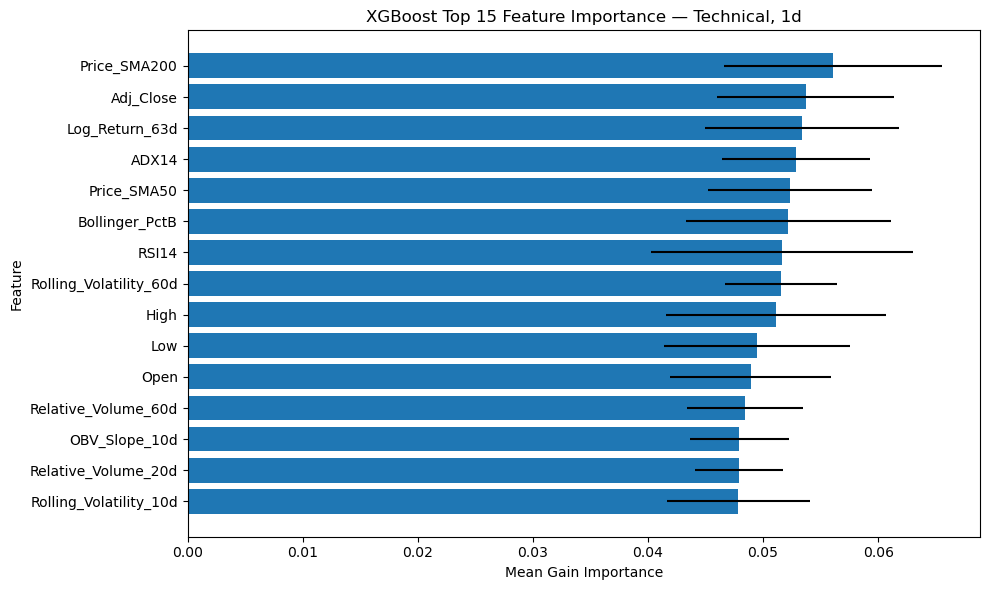

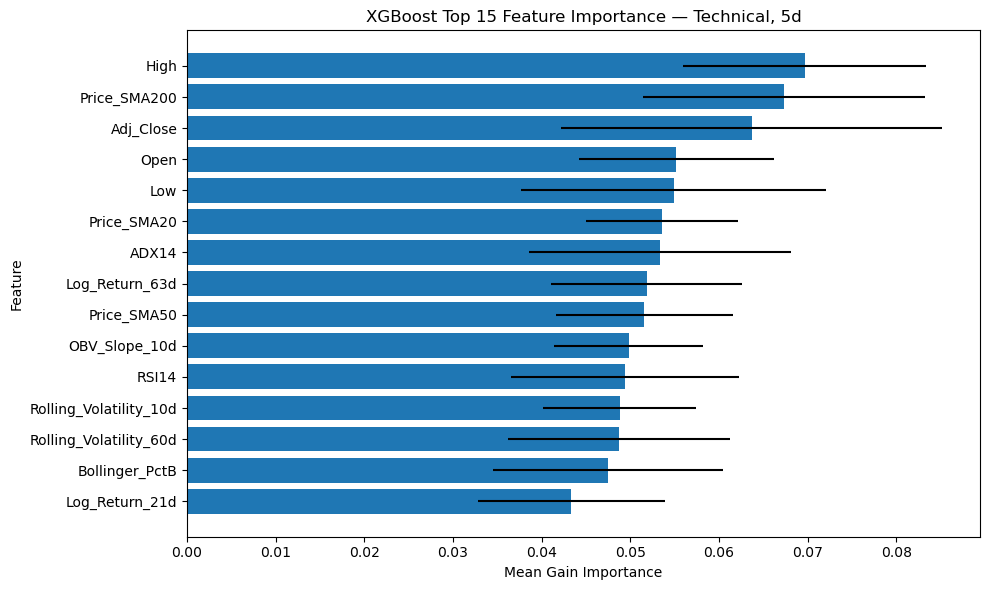

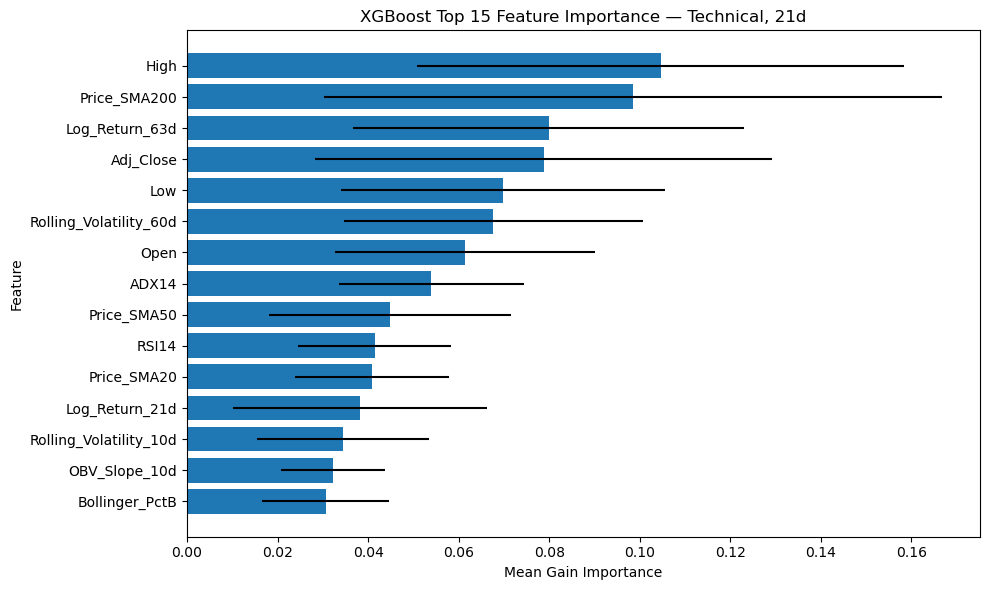

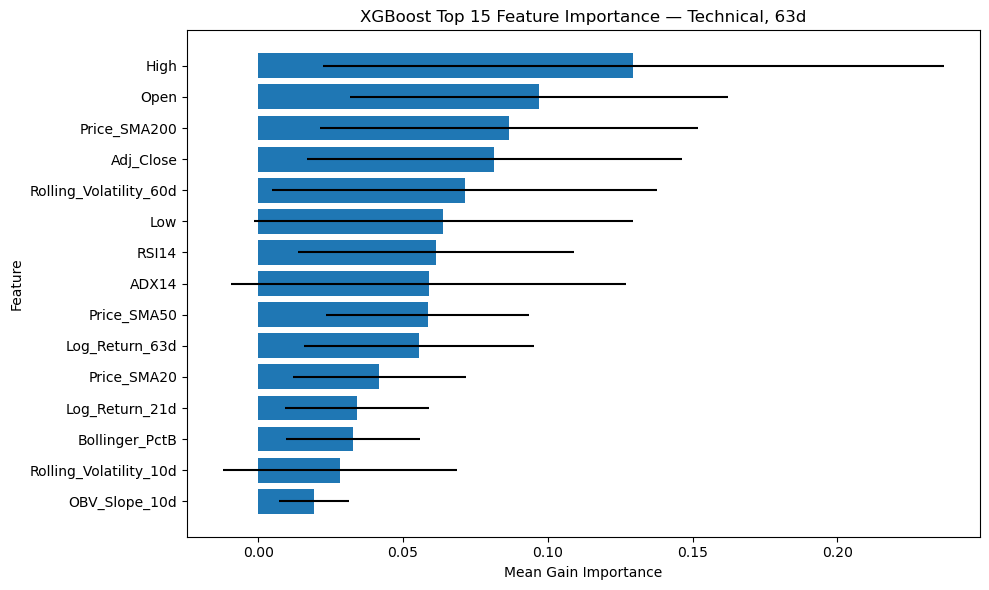

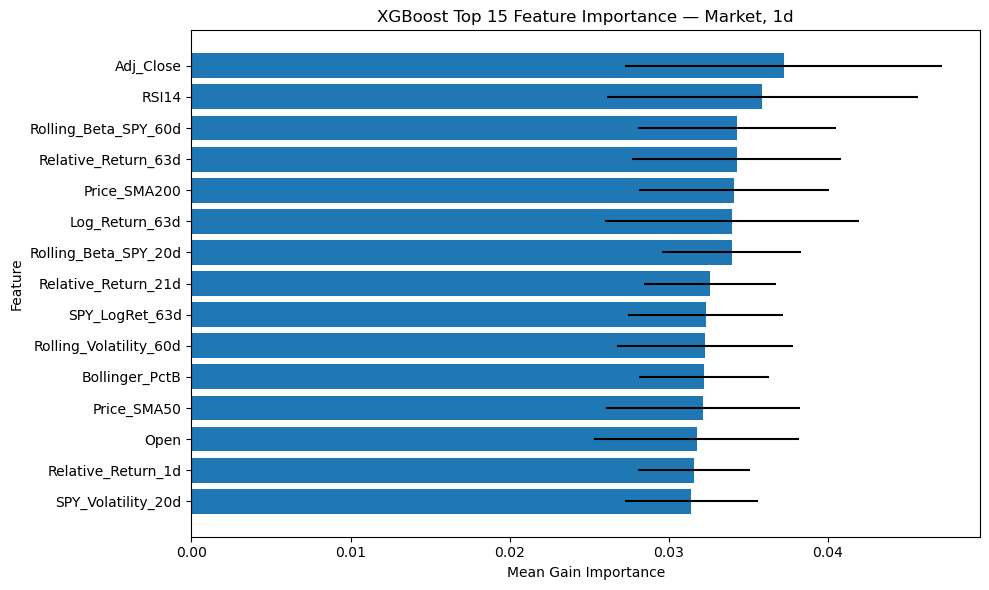

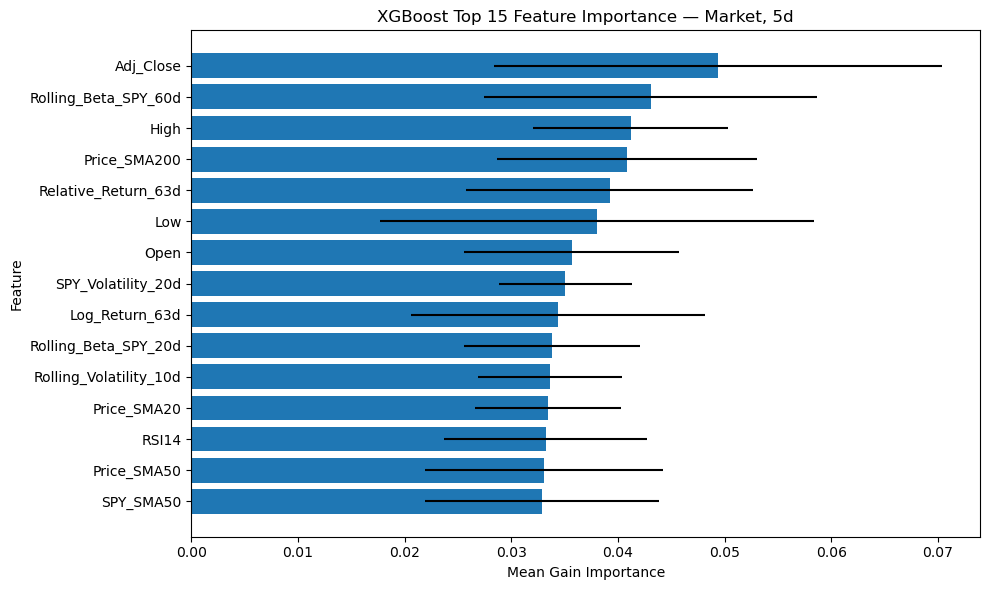

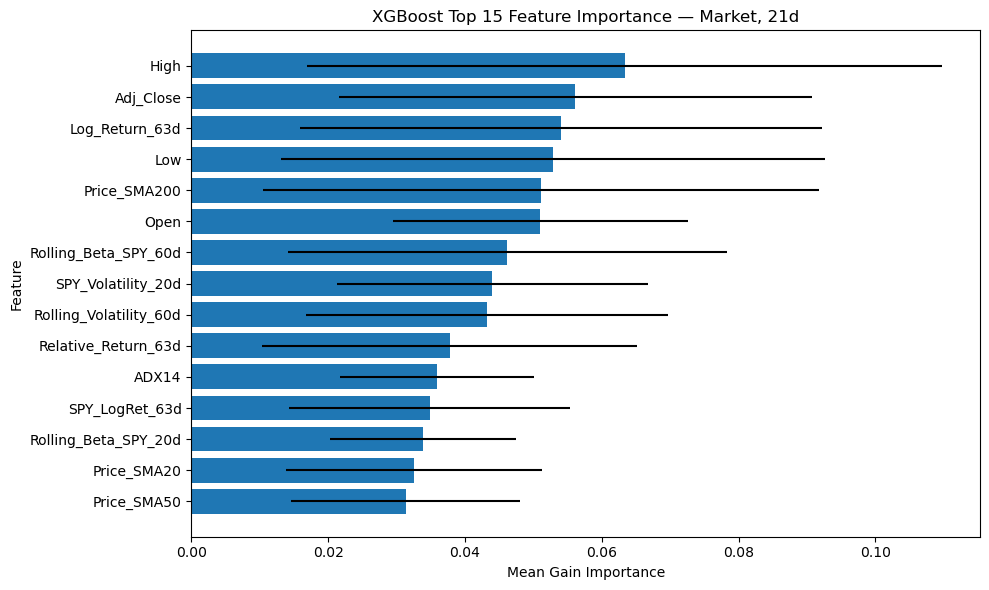

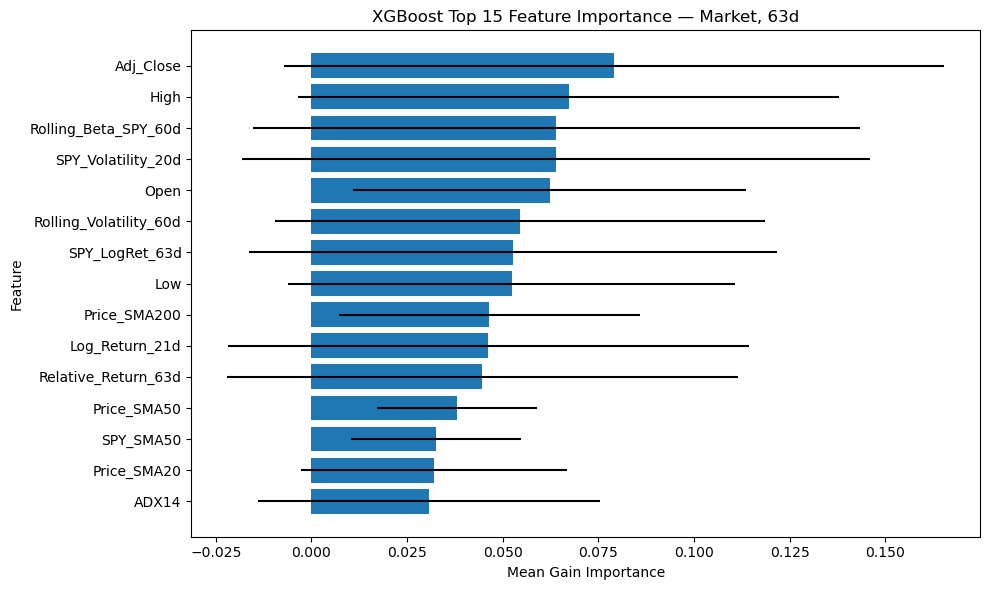

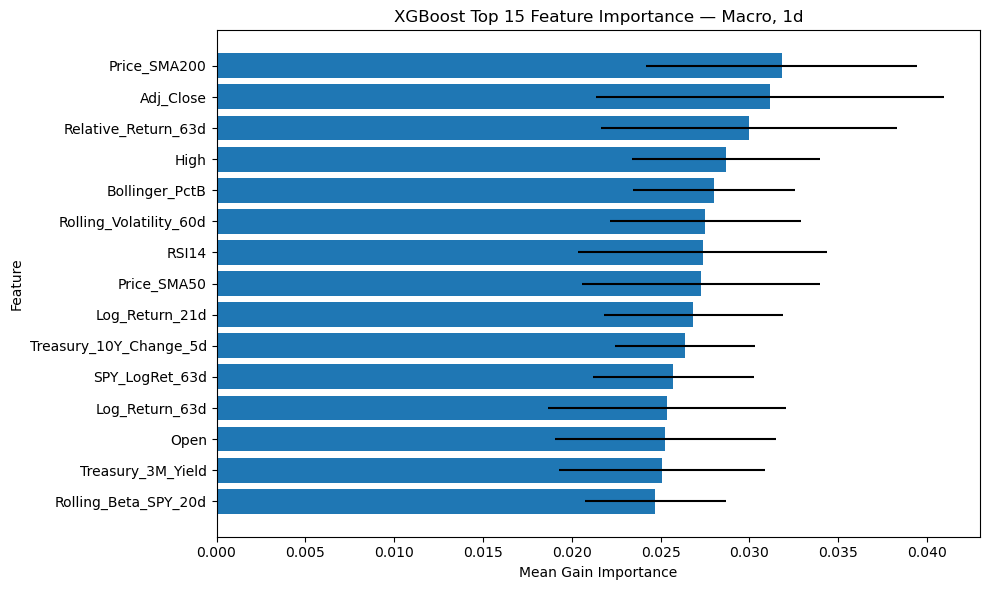

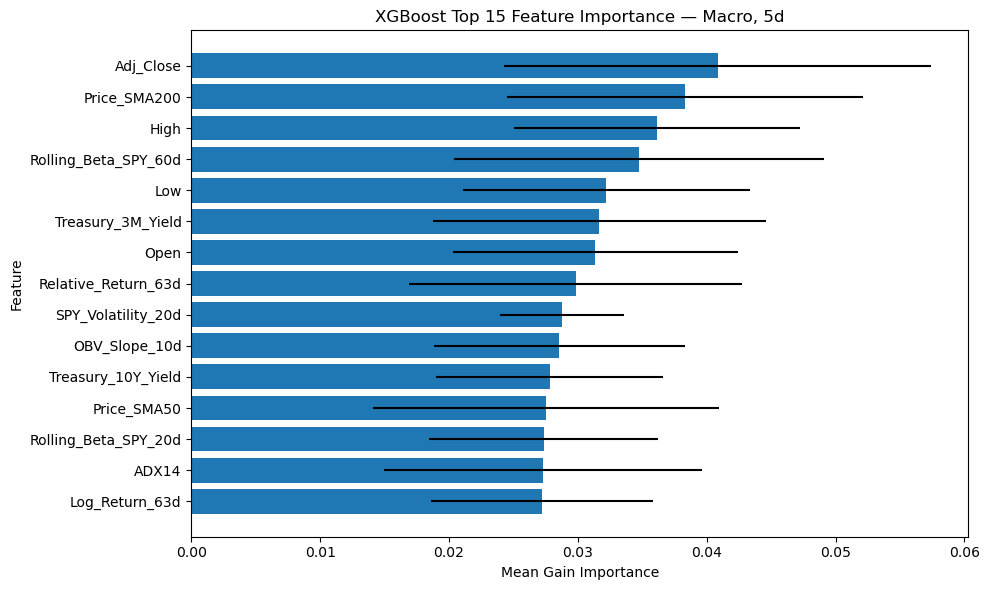

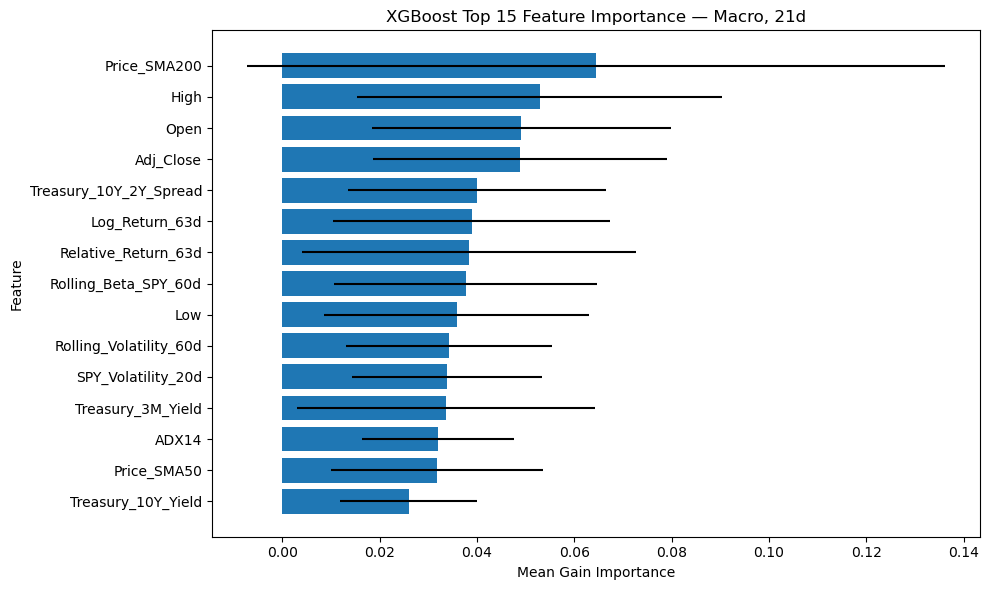

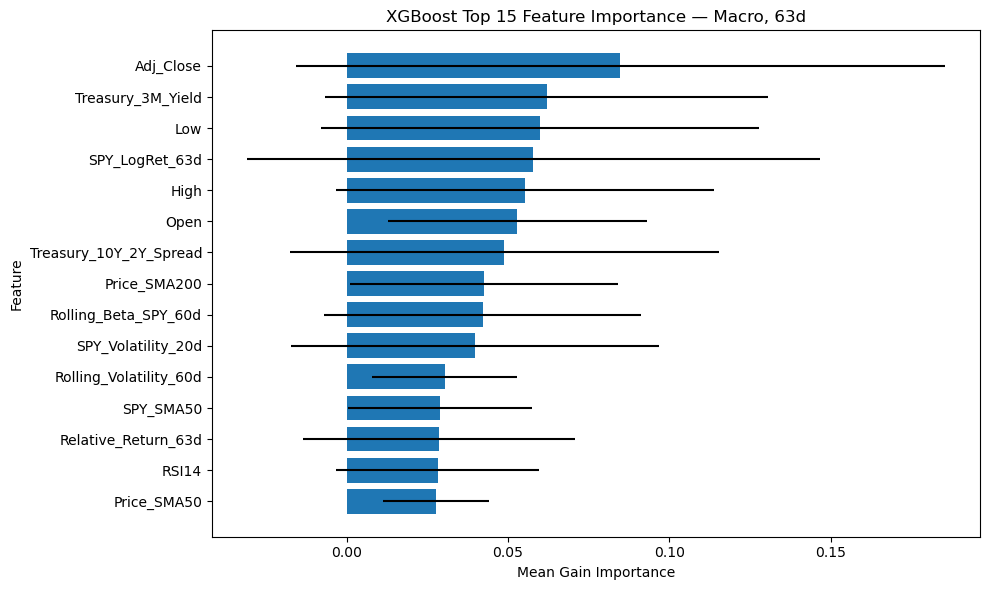

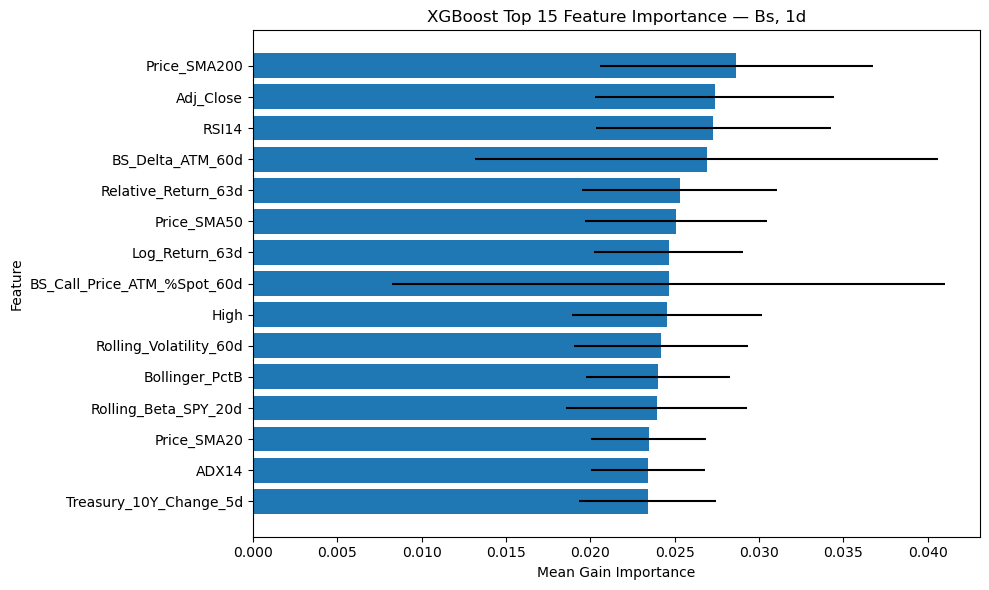

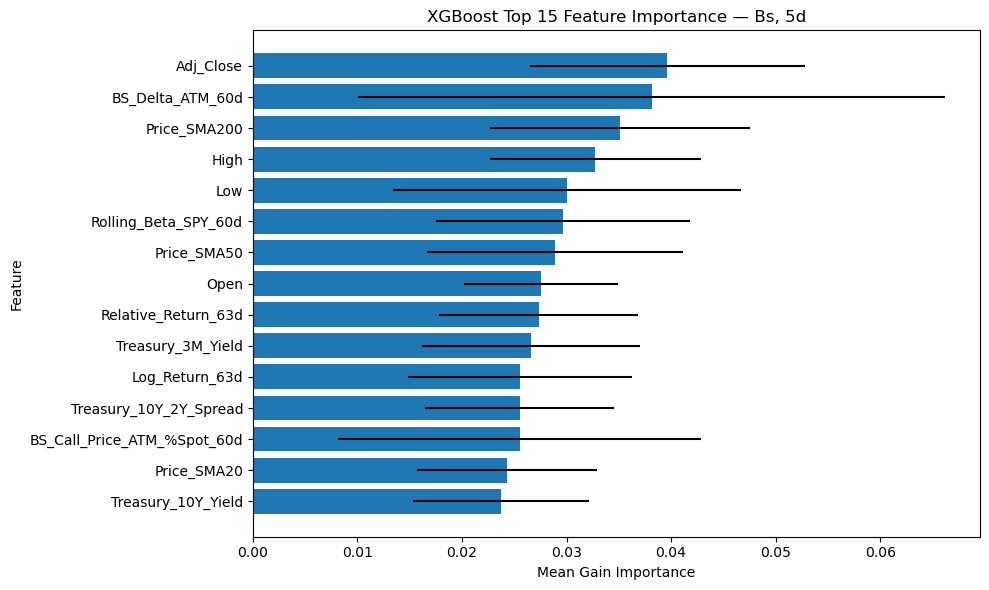

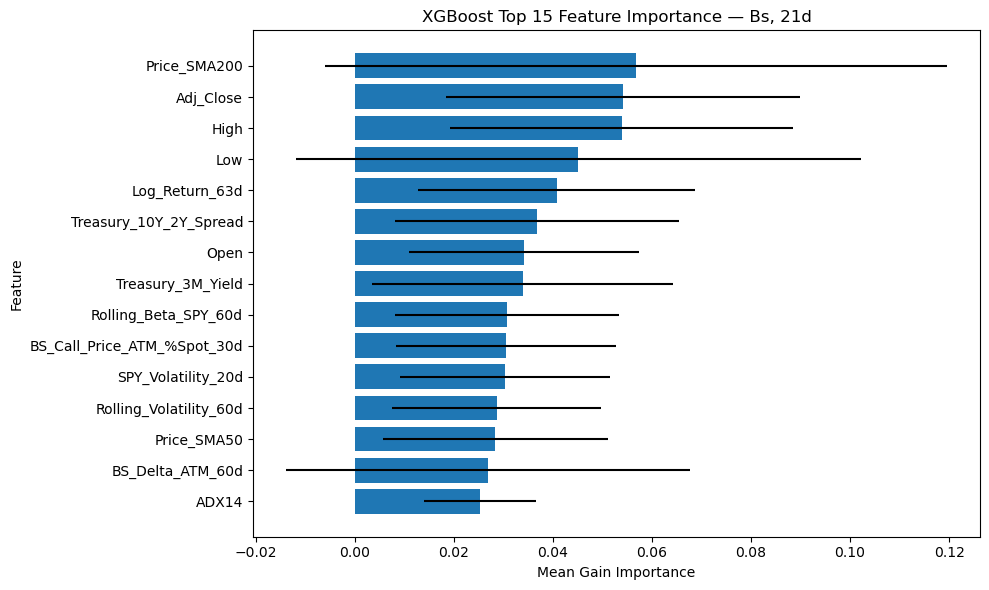

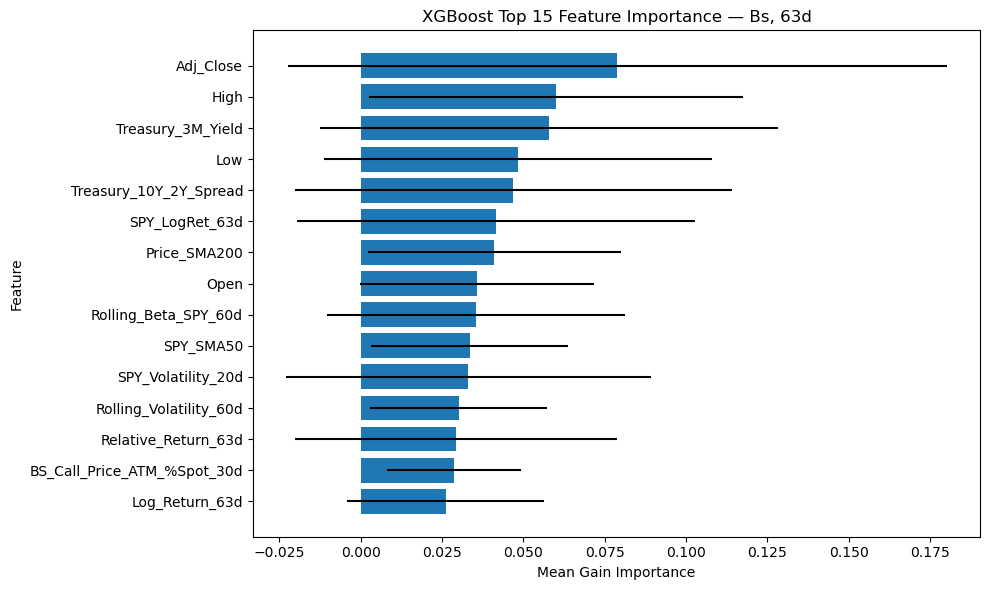

In [193]:
#Plot top features
for layer in layers:
    for h in horizons:
        plot_data = (xgb_importance_summary[(xgb_importance_summary["Layer"] == layer) &
                (xgb_importance_summary["Horizon"] == h)].nlargest(15, "Mean_Importance")
                     .sort_values("Mean_Importance"))

        if plot_data.empty:
            continue

        plt.figure(figsize=(10, 6))

        plt.barh(plot_data["Feature"], plot_data["Mean_Importance"],
                 xerr=plot_data["Std_Importance"].fillna(0))

        plt.title(f"XGBoost Top 15 Feature Importance — {layer.title()}, {h}d")
        plt.xlabel("Mean Gain Importance")
        plt.ylabel("Feature")
        plt.tight_layout()
        plt.show()

In [197]:
#Give features that consistently ranked high
xgb_ranks = xgb_importance_summary.copy()

xgb_ranks["Rank"] = (xgb_ranks.groupby(["Layer", "Horizon"])["Mean_Importance"]
                     .rank(method="min", ascending=False))

rank_stability = (xgb_ranks.groupby(["Layer", "Horizon", "Feature"])
                  .agg(Average_Rank=("Rank", "mean"),
                       Rank_Std=("Rank", "std"),
                       Folds=("Rank", "count")).reset_index())

rank_stability.sort_values(["Layer", "Horizon", "Average_Rank"]).head(20)

,Layer,Horizon,Feature,Average_Rank,Rank_Std,Folds
16,bs,1,Price_SMA200,1.0,NaN,1
1,bs,1,Adj_Close,2.0,NaN,1
18,bs,1,RSI14,3.0,NaN,1
5,bs,1,BS_Delta_ATM_60d,4.0,NaN,1
22,bs,1,Relative_Return_63d,5.0,NaN,1
17,bs,1,Price_SMA50,6.0,NaN,1
11,bs,1,Log_Return_63d,7.0,NaN,1
3,bs,1,BS_Call_Price_ATM_%Spot_60d,8.0,NaN,1
7,bs,1,High,9.0,NaN,1
28,bs,1,Rolling_Volatility_60d,10.0,NaN,1
